# PLD Filipino (FIL): dataset analysis and G2P transcription

This notebook analyses the Filipino/Tagalog part of the UP DSP Philippine Languages Database (`.data/MDC/UP-DSP-PLD/PLD/FIL`) and builds phonemic (IPA) targets for fine-tuning a phoneme recognition model.

**Contents**
1. Parsing the session logs
2. Speakers
3. Recordings and prompt categories
4. Cleaning the grapheme transcripts
5. Spontaneous speech: not used (no proper label)
6. Vocabulary and code-switching (Taglish)
7. G2P
   - 7.1 Pronunciation sources: Wiktionary broad IPA
   - 7.2 Coverage of the corpus vocabulary
   - 7.3 Epitran fallback, evaluated against Wiktionary
   - 7.4 Correction rules for Epitran
   - 7.5 Morphology: what is (and isn't) derived from Wiktionary roots
   - 7.6 Numbers and acronyms
   - 7.7 Converting every transcript
   - 7.8 Names: choosing the reading from the recordings
8. Output file
9. Summary and limitations

**G2P policy** (in order of preference, per word):
1. Wiktionary **broad** IPA (`/.../`, not the narrow `[...]` transcription): Tagalog from the kaikki.org Wiktionary extract, English from WikiPron (US English, also scraped from Wiktionary); English words missing from WikiPron are looked up in kaikki.org's English Wiktionary extract
2. Wiktionary root + a phonological rule, only where the rule is exact (linker `-ng`/`-g`, clitics `'t`/`'y`, English `-s`/`-ed`/`-ing`)
3. Epitran `tgl-Latn`, plus correction rules that were each tested against the Wiktionary lexicon

Two decisions apply to every label:
- **No glottal stops.** `ʔ` is removed from every pronunciation (section 7.1).
- **Names are read the way the speakers read them.** For personal names, places, companies and dishes that Tagalog Wiktionary does not have, the reading is chosen from a few candidates by listening to the recordings with a phoneme recogniser (section 7.8).

In [1]:
import os
import re
import sys
import glob
import json
import wave
import random
import unicodedata
import urllib.request
from collections import Counter, defaultdict
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ftfy
import epitran
import panphon
import panphon.distance
from wordfreq import zipf_frequency
from IPython.display import display

REPO = os.path.abspath("../..")
DATA_DIR = os.path.join(REPO, ".data/MDC/UP-DSP-PLD/PLD/FIL")
OUT_DIR = os.path.dirname(DATA_DIR)
KAIKKI_URL = "https://kaikki.org/dictionary/Tagalog/kaikki.org-dictionary-Tagalog.jsonl"
KAIKKI_PATH = os.path.join(REPO, ".data/wiktionary/kaikki.org-dictionary-Tagalog.jsonl")
WIKIPRON_URL = "https://raw.githubusercontent.com/CUNY-CL/wikipron/master/data/scrape/tsv/eng_latn_us_broad.tsv"
WIKIPRON_EN_PATH = os.path.join(REPO, ".data/wikipron/eng_latn_us_broad.tsv")
OUT_CSV = os.path.join(OUT_DIR, "FIL_g2p.csv")
OUT_SPEAKERS_CSV = os.path.join(OUT_DIR, "FIL_speakers.csv")

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# chart style: one hue per series, recessive axes and grid
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})

## 1. Parsing the session logs

Each speaker folder holds one `.log` per recording session plus the `.wav` files. A log has:
- a **header** of `Key = "value"` lines with session and speaker details (normally lines 1–13)
- one **utterance line** per recording: `<file>.wav  "<prompt list>"  "<text>"`

The header is parsed by pattern rather than by line number because it is not always 13 lines (see the anomalies below).

In [2]:
HEADER_RE = re.compile(r"^\W*(\w+)\s*=\s*(.*?)\s*$")  # \W* skips stray leading characters
UTT_RE = re.compile(r'^(?P<wav>\S+)\s+"(?P<prompt>[^"]*)"\s+"(?P<text>.*)"\s*$')
HEADER_KEY_FIXES = {"SpekaerDialect": "SpeakerDialect"}


def parse_log(path):
    session, utterances, anomalies = {}, [], []
    last_key = None
    lines = open(path, encoding="utf-8-sig", errors="replace").read().splitlines()
    for line in lines:
        utt, header = UTT_RE.match(line), HEADER_RE.match(line)
        if utt:
            last_key = None
            if not utt["wav"].lower().endswith(".wav"):
                anomalies.append(("utterance without a .wav filename", line))
                continue
            utterances.append({"wav": os.path.relpath(os.path.join(os.path.dirname(path), utt["wav"]), DATA_DIR), "prompt_file": utt["prompt"], "raw_text": utt["text"]})
        elif header and not utterances:
            key = HEADER_KEY_FIXES.get(header[1], header[1])
            if key != header[1]:
                anomalies.append((f"misspelled header key {header[1]}", line))
            if not line.startswith(header[1]):
                anomalies.append(("stray characters before header key", line))
            last_key = key
            session[key] = header[2].strip('"')
        elif last_key and line.strip():
            anomalies.append((f"multi-line header value ({last_key})", line))
            session[last_key] = (session[last_key] + " " + line.strip().strip('"')).strip()
        elif line.strip():
            anomalies.append(("unparseable line", line))
    session["log_file"] = os.path.relpath(path, DATA_DIR)
    return session, utterances, anomalies


sessions, rows, anomalies = [], [], []
for log_path in sorted(glob.glob(os.path.join(DATA_DIR, "*", "*.log"))):
    session, utterances, bad = parse_log(log_path)
    sessions.append(session)
    rows += [{"SpeakerID": session.get("SpeakerID"), "SessionID": session.get("SessionID"), **u} for u in utterances]
    anomalies += [(os.path.basename(log_path), kind, line[:110]) for kind, line in bad]

sessions_df = pd.DataFrame(sessions)
df = pd.DataFrame(rows)
anomalies_df = pd.DataFrame(anomalies, columns=["log", "anomaly", "line"])
print(f"{len(sessions_df)} session logs, {sessions_df.SpeakerID.nunique()} speakers, {len(df):,} utterance lines")
anomalies_df.groupby("anomaly").agg(count=("log", "size"), logs=("log", lambda s: ", ".join(sorted(set(s)))))

138 session logs, 136 speakers, 52,477 utterance lines


,count,logs
anomaly,,
misspelled header key SpekaerDialect,8,"0002.110816.100658.log, 0105.111124.050515.log, 0106.111124.050337.log, 0107.111124.020026.log, 0108.111125.052614.l..."
multi-line header value (SessionComments),1,0140.120118.021723.log
multi-line header value (SpeakerComments),1,0106.111124.050337.log
stray characters before header key,1,0003.110816.035620.log
utterance without a .wav filename,26,"0004.110817.065525.log, 0086.110923.010330.log, 0156.120228.081412.log"


In [3]:
anomalies_df.drop_duplicates("anomaly")

,log,anomaly,line
0,0002.110816.100658.log,misspelled header key SpekaerDialect,"SpekaerDialect = ""Tagalog-Batangas"""
1,0003.110816.035620.log,stray characters before header key,"`SessionID = ""110816.035620"""
2,0004.110817.065525.log,utterance without a .wav filename,"NOT_RECORDED ""TGL_spontaneous.txt"" ""Banggitin ang mga pinakapaborito mong putahe o pagkain. Ilarawan ang laha"
6,0106.111124.050337.log,multi-line header value (SpeakerComments),"80Hz hpf"""
9,0140.120118.021723.log,multi-line header value (SessionComments),"0dB preatt"""


## 2. Speakers

Some speakers have two sessions (two logs in one folder), so speaker statistics are computed on one row per `SpeakerID`.
Dialect fields are free text (`Tagalog - Rizal`, `Tagalog-Rizal`, `Tagalog Rizal`), so they are normalised before counting.

In [4]:
def normalize_dialect(s):
    if not isinstance(s, str) or not s.strip():
        return "unknown"
    s = re.sub(r"[()]", " ", s)
    s = re.sub(r"\s*[-,/]\s*|\s+", " ", s.strip()).title()
    return s


speakers = sessions_df.drop_duplicates("SpeakerID").copy()
speakers["age"] = pd.to_numeric(speakers.SpeakerAge, errors="coerce")
speakers["gender"] = speakers.SpeakerGender.str.strip().str.lower()
for col in ["SpeakerDialect", "MotherDialect", "FatherDialect"]:
    speakers[col + "_norm"] = speakers[col].map(normalize_dialect)
speakers["profession"] = speakers.SpeakerProfession.str.strip().str.lower()
print("sessions per speaker:", sessions_df.SpeakerID.value_counts().value_counts().to_dict())
print("gender:", speakers.gender.value_counts().to_dict())
speakers.age.describe().round(1).to_frame("age").T

sessions per speaker: {1: 134, 2: 2}
gender: {'female': 81, 'male': 55}


,count,mean,std,min,25%,50%,75%,max
age,136.0,20.7,5.1,15.0,18.0,19.5,21.0,55.0


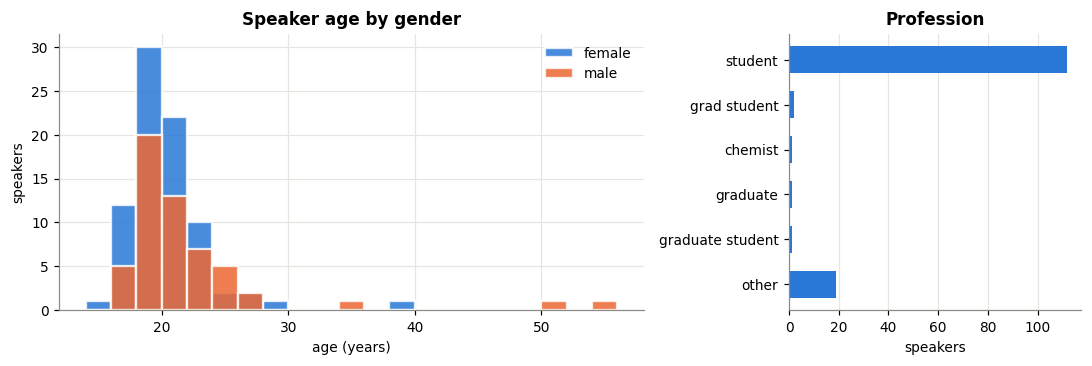

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1]})
bins = np.arange(speakers.age.min() // 2 * 2, speakers.age.max() + 3, 2)
for gender, color in [("female", BLUE), ("male", ORANGE)]:
    axes[0].hist(speakers.loc[speakers.gender == gender, "age"], bins=bins, color=color, alpha=0.85, label=gender, edgecolor="white", linewidth=1.5)
axes[0].set(title="Speaker age by gender", xlabel="age (years)", ylabel="speakers")
axes[0].legend(frameon=False)
prof = speakers.profession.replace({"": "unknown"}).value_counts()
prof = pd.concat([prof.head(5), pd.Series({"other": prof.iloc[5:].sum()})]) if len(prof) > 6 else prof
axes[1].barh(prof.index[::-1], prof.values[::-1], color=BLUE, height=0.6)
axes[1].set(title="Profession", xlabel="speakers")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [6]:
dialect_tbl = pd.DataFrame({
    "speaker": speakers.SpeakerDialect_norm.value_counts(),
    "mother": speakers.MotherDialect_norm.value_counts(),
    "father": speakers.FatherDialect_norm.value_counts(),
}).fillna(0).astype(int).sort_values("speaker", ascending=False)
print(f"{len(dialect_tbl)} distinct (normalised) dialect labels")
dialect_tbl.head(20)

67 distinct (normalised) dialect labels


,speaker,mother,father
Tagalog Laguna,22,12,14
Tagalog Bulacan,16,17,10
Tagalog Rizal,15,9,8
Tagalog Quezon,14,10,13
Tagalog Batangas,14,17,17
Tagalog Nueva Ecija,13,12,10
Tagalog Cavite,12,7,9
Tagalog Bataan,5,4,4
Tagalog Oriental Mindoro,4,2,3
Tagalog Marinduque,4,5,5


In [7]:
def dialect_family(s):
    s = s.lower()
    if "tagalog" in s or "filipino" in s:
        return "Tagalog/Filipino"
    if s == "unknown":
        return "unknown"
    return "other Philippine language"


fam = pd.DataFrame({who: speakers[col + "_norm"].map(dialect_family).value_counts() for who, col in [("speaker", "SpeakerDialect"), ("mother", "MotherDialect"), ("father", "FatherDialect")]}).fillna(0).astype(int)
both_parents_tl = (speakers.MotherDialect_norm.map(dialect_family) == "Tagalog/Filipino") & (speakers.FatherDialect_norm.map(dialect_family) == "Tagalog/Filipino")
print(f"speakers with both parents Tagalog/Filipino: {both_parents_tl.sum()} / {len(speakers)}")
fam

speakers with both parents Tagalog/Filipino: 95 / 136


,speaker,mother,father
Tagalog/Filipino,135,111,108
other Philippine language,1,25,28


**Interpretation.**
- **136 speakers** (81 female, 55 male: 60/40). Two speakers (0000, 0003) recorded two sessions.
- **The sample is young and mostly students.** Median age is 19.5, three quarters are 21 or younger, and only a handful are over 30. About 110 of 136 list "student". A model fine-tuned on this data will be tuned to young-adult voices; children and older speakers are essentially absent.
- **Dialect:** all but one speaker self-report Tagalog. The regional labels are concentrated in Southern Tagalog and Central Luzon: Laguna, Bulacan, Rizal, Batangas, Quezon, Nueva Ecija, Cavite. Batangas and Marinduque speakers matter for the `_Shib` dialect prompts (section 3).
- **41 speakers (30%) have at least one parent whose language is not Tagalog** (Ilocano, Bisaya, Aklanon, Kinaray-a, ...). The speakers are Tagalog-dominant, but some substrate influence on pronunciation is possible.
- **Consequence for G2P:** the dictionary pronunciations below are Standard (Manila) Tagalog. The IPA targets are therefore canonical phonemic forms, not a record of each speaker's regional realisation.

## 3. Recordings and prompt categories

Durations are read from the WAV headers (cheap: no audio is decoded). The prompt-list names encode the elicitation task:

| category | prompt lists | content |
|---|---|---|
| isolated words | `TGL_Iso_*` (no `_Shib`) | single words / short names by topic (kinship, body parts, time, ...) |
| named entities | `TGL_Airlines.txt`, `TGL_Cities.txt`, ... | names of companies, hotels, places, people |
| read sentences | `TGL_Utt_*`, `TGLNEW_*` | sentences: greetings, questions, proverbs, news, medical, literature, ... |
| dialect (`_Shib`) | `*_Shib.txt` | regional words/sentences (Batangas, Marinduque, Mindoro, Morong, ...), often with a dialect note in `()` |
| digits | `Random Digit` | numbers 0–100 |
| spontaneous | `TGL_spontaneous.txt`, `TGL_Spo_xa?.txt` | free speech answering a question (see section 5) |
| unknown | empty prompt list | sessions whose log has `""` as prompt list |

In [8]:
SPONTANEOUS_PROMPTS = {"TGL_spontaneous.txt", "TGL_Spo_xaa.txt", "TGL_Spo_xab.txt", "TGL_Spo_xac.txt"}


def prompt_category(p):
    if p in SPONTANEOUS_PROMPTS:
        return "spontaneous"
    if p == "Random Digit":
        return "digits"
    if p == "":
        return "unknown"
    if "_Shib" in p:
        return "dialect (Shib)"
    if p.startswith("TGL_Iso_"):
        return "isolated words"
    if p.startswith(("TGL_Utt_", "TGLNEW_")):
        return "read sentences"
    return "named entities"


def wav_duration(rel):
    path = os.path.join(DATA_DIR, rel)
    if not os.path.exists(path):
        return np.nan
    try:
        with wave.open(path) as w:
            return w.getnframes() / w.getframerate()
    except (EOFError, wave.Error):
        return -1.0  # file exists but its header can't be read


df["category"] = df.prompt_file.map(prompt_category)
df["wav_exists"] = df.wav.map(lambda p: os.path.exists(os.path.join(DATA_DIR, p)))
df["duration_s"] = df.wav.map(wav_duration)
df["wav_readable"] = df.wav_exists & (df.duration_s >= 0)
print("unreadable/truncated wav files:", df.loc[df.wav_exists & ~df.wav_readable, "wav"].tolist())
df.loc[~df.wav_readable, "duration_s"] = np.nan
df["empty_audio"] = df.wav_readable & (df.duration_s < 0.1)
print("wav files shorter than 0.1 s:", int(df.empty_audio.sum()))

formats = Counter()
for rel in df.loc[df.wav_readable, "wav"].sample(500, random_state=0):
    with wave.open(os.path.join(DATA_DIR, rel)) as w:
        formats[(w.getframerate(), w.getnchannels(), 8 * w.getsampwidth())] += 1
print("audio format (rate, channels, bits) on a 500-file sample:", dict(formats))
print(f"utterance lines with no audio file: {(~df.wav_exists).sum():,} "
      f"(speaker folders without any audio: {sorted(df.loc[~df.wav_exists, 'SpeakerID'].unique())})")
print(f"total audio: {df.duration_s.sum() / 3600:.1f} h")

summary = df.groupby("category").agg(
    utterances=("wav", "size"), with_audio=("wav_exists", "sum"), hours=("duration_s", lambda s: s.sum() / 3600),
    median_s=("duration_s", "median"), speakers=("SpeakerID", "nunique"), prompt_lists=("prompt_file", "nunique"),
).sort_values("hours", ascending=False)
summary.round(2)

unreadable/truncated wav files: ['0002/0002.110816.100658.0492.wav']
wav files shorter than 0.1 s: 0
audio format (rate, channels, bits) on a 500-file sample: {(16000, 1, 16): 500}
utterance lines with no audio file: 1,483 (speaker folders without any audio: ['0075', '0077', '0088', '0101', '0102', '0103', '0104'])
total audio: 52.1 h


,utterances,with_audio,hours,median_s,speakers,prompt_lists
category,,,,,,
read sentences,23846,23846,35.78,3.88,129,23
isolated words,22063,22063,9.63,1.31,107,16
spontaneous,298,298,3.55,42.41,128,4
dialect (Shib),2907,2907,2.00,2.42,107,19
named entities,790,790,0.63,2.68,16,9
digits,1090,1090,0.47,1.44,107,1
unknown,1483,0,0.00,NaN,7,1


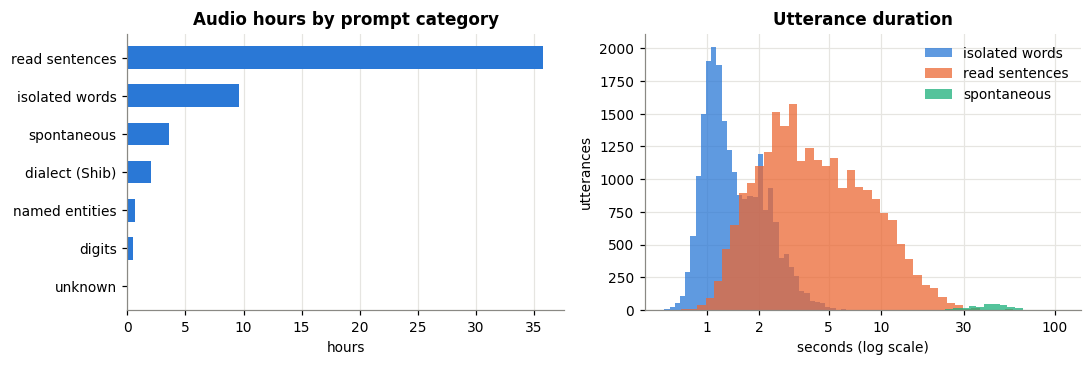

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
s = summary.sort_values("hours")
axes[0].barh(s.index, s.hours, color=BLUE, height=0.6)
axes[0].set(title="Audio hours by prompt category", xlabel="hours")
axes[0].grid(axis="y", visible=False)
for cat, color in [("isolated words", BLUE), ("read sentences", ORANGE), ("spontaneous", AQUA)]:
    d = df.loc[(df.category == cat) & df.wav_exists, "duration_s"]
    axes[1].hist(np.log10(d), bins=40, color=color, alpha=0.75, label=cat)
axes[1].set(title="Utterance duration", xlabel="seconds (log scale)", ylabel="utterances")
ticks = [1, 2, 5, 10, 30, 100]
axes[1].set_xticks(np.log10(ticks), ticks)
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

In [10]:
per_speaker = df[df.wav_exists].groupby("SpeakerID").agg(utterances=("wav", "size"), minutes=("duration_s", lambda s: s.sum() / 60))
print(per_speaker.describe().round(1).T)
for cat in ["isolated words", "named entities", "read sentences", "dialect (Shib)", "digits"]:
    print(f"\n{cat}:", df[df.category == cat].raw_text.drop_duplicates().sample(5, random_state=1).tolist())

            count   mean   std    min    25%    50%    75%    max
utterances  129.0  395.3  94.5  128.0  393.0  408.0  442.0  776.0
minutes     129.0   24.2   5.8   15.2   20.5   22.0   27.9   46.8

isolated words: ['Volante', 'tita', 'Ilagan', "ikadalawampu't isang", 'buto']

named entities: ['Pandesal', 'Bulkang Taal', 'Monumento ni Bonifacio', 'Mati', 'Rey']

read sentences: ['Nagkaroon ng traffic dahil sa aksidente.', 'Paabot ng flashcard.', 'Nang mamatay ang mga magulang niya, at magulang ni Fidel, naipon ni Aling Laura ang ilang bulaklak na nalagas sa korona upang ialay sa harap ng Birhen.', 'Ikaw pala iyan. / Gumamit siya ng pala (shovel) sa paghuhukay.', 'Nanghihiram ba kayo ng toothbrush?']

dialect (Shib): ['Punasi mo muna iyang lamesa', 'la-ang\t\t(Batangas, Marinduque)', 'Buksan mo ang telebisyon nata. (Batangan)', 'Daniel Z. Romualdez Airport', 'Na tulad sa inang tunay na nagpala']

digits: ['dalawampu', '60', "apatnapu't lima", 'siyam', '82']


**Interpretation.**
- **52.1 h of audio**, all 16 kHz mono 16-bit (on the sample checked), which matches the 16 kHz input expected by the repo's wav2vec2 models with no resampling.
- **Read sentences dominate** (35.8 h, ~69% of audio). Isolated words are the most numerous utterances (22k) but short (median 1.3 s), so they add only 9.6 h. Named entities were recorded by only 16 speakers.
- **Missing or broken audio:** 1,483 utterance lines from 7 speaker folders (0075, 0077, 0088, 0101–0104) have no audio, and these logs also have an empty prompt-list field. One WAV (`0002/0002.110816.100658.0492.wav`) is truncated.
- **Balanced per speaker:** median ~408 utterances and ~22 min each, so no single speaker dominates. A speaker-disjoint train/test split is straightforward.
- **Durations** span 0.5 s to ~110 s. Read sentences have a long right tail (up to ~30 s) and spontaneous answers average ~40 s; long utterances may need chunking or a length cap for CTC fine-tuning on limited GPU memory.
- The `_Shib` (shibboleth) prompts contain dialect-specific words and sentences (`ngay-on`, `la-ang`, `Punasi mo muna iyang lamesa`). The dialect note in `()` is removed as a gloss, and the word is transcribed from its spelling.

## 4. Cleaning the grapheme transcripts

The `"<text>"` field is the prompt the speaker read. Before G2P it needs cleaning:

| issue | example | handling |
|---|---|---|
| parentheses: glosses, translations, dialect notes, stage directions | `ako (I)`, `ngay-on (Batangas, Marinduque)`, `Iguhit ang (bituin) kung tama` | **removed with their content** (not read aloud) |
| nested double quotes: quoted speech inside the prompt | `""Naku", ang himutok ng matsing, ..."` | **quote marks removed, text kept** (it is read) |
| mojibake: double-encoded UTF-8 and cp1252 bytes | `hapÃºnan`, `ABS\x96CBN` | fixed with `ftfy` → `hapúnan`, `ABS–CBN` |
| `/` joining two sentences read in one recording (minimal-pair prompts) | `May buhay sa basura. / Nakahuli si Bimbo ...` | `/` removed |
| bracketed tokens that are read aloud | `ICRO [space] FIND` | brackets removed, word kept |
| `&`, symbols | `Procter & Gamble`, `™`, `®` | `&` → `and`; symbols removed |
| digits | `85`, `$62.7 billion`, `2003` | verbalised in section 7.6 |

In [11]:
def remove_parentheticals(text):
    prev = None
    while prev != text:  # repeat for nested parentheses
        prev = text
        text = re.sub(r"\([^()]*\)", " ", text)
    return text.replace("(", " ").replace(")", " ")  # unbalanced leftovers


def clean_transcript(text):
    text = ftfy.fix_text(text)  # mojibake, curly quotes, C1 control characters
    text = unicodedata.normalize("NFC", text)
    text = text.replace("﻿", "").replace("­", "").replace("\xa0", " ")
    text = remove_parentheticals(text)
    text = text.replace('"', " ")
    text = re.sub(r"\[([^\[\]]*)\]", r" \1 ", text)
    text = text.replace("&", " and ").replace("/", " ")
    text = re.sub(r"[™®©¡¿«»¬±º²³`]", " ", text)
    text = re.sub(r"[–—]", "-", text)
    text = re.sub(r"\s+", " ", text).strip()
    return re.sub(r"\s+([,.;:!?])", r"\1", text)


issues = {
    "parentheses": df.raw_text.str.contains(r"[()]"),
    "nested quotes": df.raw_text.str.contains('"'),
    "mojibake": df.raw_text.map(lambda t: ftfy.fix_text(t) != t and bool(re.search(r"Ã|Â|[\x80-\x9f]", t))),
    "slash": df.raw_text.str.contains("/"),
    "brackets": df.raw_text.str.contains(r"\["),
    "digits": df.raw_text.map(lambda t: bool(re.search(r"\d", remove_parentheticals(t)))),
}
print(pd.DataFrame({k: v.groupby(df.category).sum() for k, v in issues.items()}).T)

df["text"] = df.raw_text.map(clean_transcript)
examples = pd.concat([df[v].drop_duplicates("raw_text").sample(min(2, v.sum()), random_state=3) for k, v in issues.items() if k != "digits"])
examples[["raw_text", "text"]]

category       dialect (Shib)  digits  isolated words  named entities  read sentences  spontaneous  unknown
parentheses               655       0            1504               0             676            0       71
nested quotes               0       0               0               0             732            0        0
mojibake                    0       0              18               1               0            0       86
slash                       0       0              53               0             467            0       34
brackets                    0       0               0               0               1            0        0
digits                      0     970              10               1              21            0        0


,raw_text,text
52128,Pang walo (8th) ang Pilipinas sa tatlongpu't dalawang bansa sa buong mundo na nakakuha ng mataas na ranking sa 'boom...,Pang walo ang Pilipinas sa tatlongpu't dalawang bansa sa buong mundo na nakakuha ng mataas na ranking sa 'booming bu...
48151,"Kasama sa roundtable discussion sina Senator Edgardo Angara, Representative Joey Salceda, National Economic and Deve...","Kasama sa roundtable discussion sina Senator Edgardo Angara, Representative Joey Salceda, National Economic and Deve..."
17063,"Babayuhin ba kita sa lusng o itatapon sa ilog? Alin ang ibig mo?""",Babayuhin ba kita sa lusng o itatapon sa ilog? Alin ang ibig mo?
47805,"""Pati raw si Mr. Kabayan, ni hindi man lang nagpasabi kung kailan uuwi, kung uuwi nga.","Pati raw si Mr. Kabayan, ni hindi man lang nagpasabi kung kailan uuwi, kung uuwi nga."
41680,ManÃ­gong bagong taon.,Manígong bagong taon.
41897,Maligayang pagbÃ¡tÃ¬.,Maligayang pagbátì.
31757,Huwag mo akong agÃ¡wan (verb) ng trabaho. / Nagpatuloy ang agawÃ¡n (noun) nilang magkapatid.,Huwag mo akong agáwan ng trabaho. Nagpatuloy ang agawán nilang magkapatid.
7990,﻿Aba! Andyan ka na pala. / Mapalad ang mga aba (poor).,Aba! Andyan ka na pala. Mapalad ang mga aba.
51087,Isusulat lamang ang text message na ICRO [space] FIND [space] Pangalan ng lungsod at ipadala sa two nine three seven...,Isusulat lamang ang text message na ICRO space FIND space Pangalan ng lungsod at ipadala sa two nine three seven. Pa...


**Interpretation.** The issues are concentrated in specific prompt types:
- **Parentheses** appear mostly in isolated-word lists (1,504 lines: glosses on minimal pairs such as `bara-bará (measure-obstruction)`) and dialect prompts (655: region notes). Left in, a gloss like `(I)` would become phones the speaker never said.
- **Nested quotes** appear only in read sentences (stories and essays with dialogue, 732 lines).
- **Mojibake** affects 105 lines, mostly in the audio-less logs. Without the fix, `ManÃ­gong` would be transcribed letter by letter as garbage.
- **`/`** joins two sentences in the minimal-pair prompts (`TGL_Utt_MinPairs.txt`). Both sentences are read in the recording, so both are kept.

## 5. Spontaneous speech: not used (no proper label)

For the `TGL_spontaneous.txt` and `TGL_Spo_xa?.txt` prompt lists, the text in the log is **the question the speaker was asked**, not what they said. For example:

> `Ikuwento sa amin ang iyong pang-araw-araw na gawain. ...` ("Tell us about your daily routine ...")

The recordings are long free-form answers (median ~40 s, versus ~1 s for isolated words), and what the speaker said is not written down anywhere in the corpus.

**Decision: spontaneous speech is not used for now.** This is because of the nature of the transcription: there is no proper label for these recordings. The only text available is the question, and using it as the label would teach the model a transcript that has nothing to do with the audio. These recordings are therefore:
- excluded from the vocabulary analysis and from G2P (no IPA is generated)
- left out of the output file `FIL_g2p.csv`

They can be added back once a proper transcription exists, either transcribed by hand or as an ASR draft that a listener corrects. That transcription would then go through the same cleaning and G2P as the read prompts. The cell below only describes what is being left out.

In [12]:
spont = df[df.category == "spontaneous"]
print(f"{len(spont)} spontaneous recordings ({spont.wav_exists.sum()} with audio, {spont.duration_s.sum() / 3600:.2f} h), "
      f"from {spont.SpeakerID.nunique()} speakers, {spont.text.nunique()} distinct questions")
print("duration (s):", spont.duration_s.describe().round(1).to_dict())
spont.groupby("text").agg(recordings=("wav", "size"), median_s=("duration_s", "median")).sort_values("recordings", ascending=False).round(1)

298 spontaneous recordings (298 with audio, 3.55 h), from 128 speakers, 17 distinct questions
duration (s): {'count': 298.0, 'mean': 42.9, 'std': 13.4, 'min': 1.8, '25%': 34.3, '50%': 42.4, '75%': 50.1, 'max': 109.4}


,recordings,median_s
text,,
"Ikuwento sa amin ang iyong pang-araw-araw na gawain. Mga sinasakyan patungo sa trabaho o paaralan, mga lakarin, at iba pa. Banggitin lahat ng maiisip mo sa iyong pang-araw-araw na karanasan.",34,45.6
Magbanggit ng isa sa mga paborito mong artistang Filipino. Puwedeng babae o lalaki. Ilarawan ang mga katangiang nagustuhan mo sa kanya. Saan mo siya napanood o pinapanood?,31,40.1
Magbanggit ng isa sa mga pinakaimportanteng personalidad sa ating bansa at ilarawan ang kanyang tungkulin o ginagawa. Hinahangaan mo ba siya o ng mga tao? Bakit?,27,41.3
Ano ang kadalasang ginagawa mo kapag may sakit ka? Ikuwento lahat ng mga posibleng gawin mo.,25,39.8
Magbanggit ng isang lugar sa Pilipinas na mairerekomenda mo para sa mga turista. Ilarawan ang lahat ng maiisip mo pati ang mga na-experience mo dito.,21,43.4
"Ilarawan sa amin ang iyong paboritong isport, hobby, o recreational activity. Ilarawan ang lahat ng maiisip mo tungkol dito.",20,40.5
Banggitin ang mga pinakapaborito mong putahe o pagkain. Ilarawan ang lahat ng maiisip mo tungkol dito.,17,45.8
"Anong trabaho ang mas pipiliin mo: mataas na suweldo pero hindi mo gusto ang trabaho, o trabahong gustong-gusto mo pero sobrang baba ng sahod? Bakit?",17,40.9
"Noong high school, anong subject o mga subject ang pinakainteresado ka? Bakit? Ilarawan lahat ng maiisip tungkol dito.",17,39.6


## 6. Vocabulary and code-switching (Taglish)

Tokens are words (letters with internal `-` or `'`), or numbers. To estimate how much English is in the prompts, each word is labelled with `wordfreq`:
it counts as **English** if it is a common English word (Zipf ≥ 3) that is clearly more frequent in English than in Filipino (difference ≥ 0.3).
The same test is used in section 7 to pick between the Tagalog and English pronunciation of a word found in both dictionaries.

In [13]:
TOKEN_RE = re.compile(r"[$]?\d+(?:[.,]\d+)*%?|[^\W\d_]+(?:['\-][^\W\d_]*)*")
EN_MARGIN, MIN_ZIPF = 0.3, 3.0


@lru_cache(maxsize=None)
def looks_english(word):
    w = word.lower()
    en, fil = zipf_frequency(w, "en"), zipf_frequency(w, "fil")
    return en >= MIN_ZIPF and en - fil >= EN_MARGIN


transcribed = df[df.category != "spontaneous"].copy()
transcribed["tokens"] = transcribed.text.map(TOKEN_RE.findall)
tok = transcribed.explode("tokens").dropna(subset=["tokens"])
tok = tok[~tok.tokens.str.contains(r"\d")]
tok["english"] = tok.tokens.map(looks_english)

vocab = Counter(tok.tokens.str.lower())
print(f"{len(tok):,} word tokens, {len(vocab):,} word types (lower-cased)")
print(f"{sum(1 for c in vocab.values() if c == 1):,} types occur once; "
      f"{transcribed.text.nunique():,} distinct prompts for {len(transcribed):,} utterances")

lang = tok.groupby("category").english.mean().to_frame("English token share")
lang["utterances with ≥1 English word"] = transcribed.assign(en=transcribed.tokens.map(lambda ts: any(looks_english(t) for t in ts if not re.search(r"\d", t)))).groupby("category").en.mean()
lang.round(3)

334,511 word tokens, 12,013 word types (lower-cased)
3,966 types occur once; 6,431 distinct prompts for 52,179 utterances


,English token share,utterances with ≥1 English word
category,,
dialect (Shib),0.129,0.183
digits,0.000,0.000
isolated words,0.205,0.173
named entities,0.300,0.363
read sentences,0.032,0.106
unknown,0.006,0.031


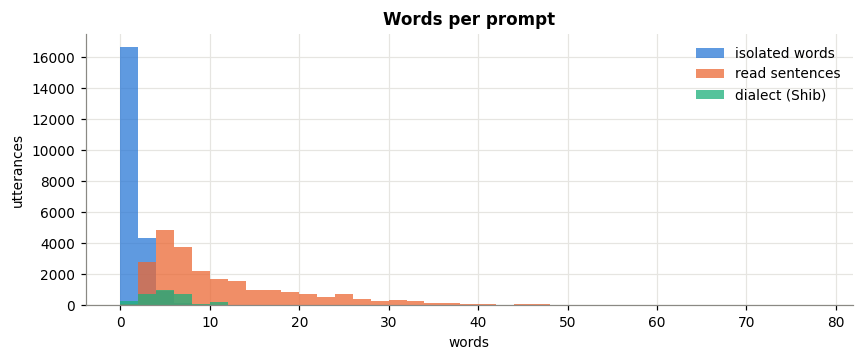

most frequent English-labelled words: [('international', 561), ('and', 454), ('of', 348), ('bank', 330), ('point', 309), ('five', 276), ('corporation', 252), ('the', 221), ('michael', 206), ('holdings', 168), ('two', 166), ('suites', 144), ('university', 137), ('pacific', 130), ('spa', 130), ('hundred', 130), ('one', 129), ('nine', 114), ('company', 112), ('percent', 112), ('to', 109), ('investments', 108), ('three', 108), ('first', 102), ('crown', 96), ('regency', 96), ('four', 96), ('water', 95), ('thousand', 92), ('all', 88)]


In [14]:
fig, ax = plt.subplots(figsize=(9, 3.2))
words_per_utt = transcribed.tokens.map(len)
for cat, color in [("isolated words", BLUE), ("read sentences", ORANGE), ("dialect (Shib)", AQUA)]:
    ax.hist(words_per_utt[transcribed.category == cat], bins=np.arange(0, 80, 2), color=color, alpha=0.75, label=cat)
ax.set(title="Words per prompt", xlabel="words", ylabel="utterances")
ax.legend(frameon=False)
plt.show()
print("most frequent English-labelled words:", Counter(tok.loc[tok.english, "tokens"].str.lower()).most_common(30))

**Interpretation.**
- **334k word tokens, 12k word types.** A third of the types occur once (names, rare words), which is why dictionary coverage below is measured on both types and tokens.
- **Prompts are reused heavily:** 6,431 distinct prompts for 52k utterances, about 8 readings each. A random utterance-level split would put the same sentence in train and test. **Split by prompt and by speaker** to measure generalisation honestly.
- **Code-switching is lexical insertion.** In read sentences only 3% of tokens are English, but 11% of sentences contain at least one English word (`traffic`, `flashcard`, `toothbrush`, `investment portfolio`). The English share is highest in named entities (30%) and isolated words (20%), driven by company, hotel and landmark names (`International`, `Bank`, `Corporation`, `Suites`). Many English-labelled tokens are also spelled-out English numbers in news prompts (`five`, `point`, `hundred`), which are read in English.
- Per-word English detection is therefore enough: sentences are Tagalog with English words inside them, rather than alternating between longer stretches of each language.

## 7. G2P

### 7.1 Pronunciation sources: Wiktionary broad IPA

- **Tagalog: kaikki.org Tagalog extract of English Wiktionary.** Each entry has the headword, its *canonical* accented spelling (`batà` "child" vs `batá` "endurance") and pronunciations. Only **broad** transcriptions (`/ˈbataʔ/`) are used, not narrow ones (`[ˈbaː.t̪ɐʔ]`), preferring those tagged *Standard Tagalog*.
- **English: WikiPron `eng_latn_us_broad`**, also scraped from Wiktionary, broad US-English IPA.

Normalisation: stress (`ˈ ˌ`), syllable dots and spaces are removed, since Epitran output has no stress and the targets should be consistent. Optional segments in parentheses (`/ˌhalo(ʔ) ˈhaloʔ/`) are dropped. Tie bars (`t͡ʃ`, `d͡ʒ`) are kept, following Wiktionary.

**Glottal stops are removed.** Wiktionary writes `ʔ` before every vowel-initial word (`/ʔako/`), between vowels (`/taʔo/`) and at the end of many words (`/bataʔ/`). In read speech it is often weak or absent, especially inside a sentence, and the spelling never shows the final one. A phoneme model trained with `ʔ` in its labels spent most of its errors on it (the largest single error class on held-out speakers). The labels therefore describe the segments speakers reliably produce, without `ʔ`. The cost is that a few minimal pairs (`bata` "child" /bataʔ/ vs `bata` "endurance" /bata/) become identical; stress, which also separates them, is already removed.

**Homographs.** Tagalog spelling usually omits accents, so `bata` can be `/ˈbataʔ/` "child" or `/baˈta/` "endurance". If the transcript writes the accent (`batá`, `subô`), the entry with that canonical spelling is used. Otherwise the **first entry** is used, which is etymology 1 on the Wiktionary page and usually the most common sense.

In [15]:
for url, path in [(KAIKKI_URL, KAIKKI_PATH), (WIKIPRON_URL, WIKIPRON_EN_PATH)]:
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print("downloading", url)
        urllib.request.urlretrieve(url, path)


def strip_marks(word):
    # remove accents but keep ñ
    d = unicodedata.normalize("NFD", word)
    return unicodedata.normalize("NFC", "".join(c for c in d if not unicodedata.combining(c) or c == "̃"))


def normalize_wiktionary_ipa(ipa):
    ipa = ipa.strip("/")
    ipa = re.sub(r"\([^)]*\)", "", ipa)
    return re.sub(r"[ˈˌ.\s|‿ʔ]", "", ipa)  # ʔ: no glottal stops in the labels


TL_LEX = defaultdict(list)  # accent-free lower-case word -> [(canonical spellings, [broad IPA, ...]), ...] in page order
TL_EXACT = {}  # exact headword (case kept) -> broad IPA, used for acronyms like "DNA"
n_entries = 0
for line in open(KAIKKI_PATH, encoding="utf-8"):
    entry = json.loads(line)
    n_entries += 1
    broad = [s for s in entry.get("sounds", []) if s.get("ipa", "").startswith("/")]
    standard = [s for s in broad if "Standard-Tagalog" in (s.get("tags") or ["Standard-Tagalog"])]
    ipas = [normalize_wiktionary_ipa(s["ipa"]) for s in (standard or broad)]
    if not ipas:
        continue
    forms = {unicodedata.normalize("NFC", f["form"].lower()) for f in entry.get("forms", []) if "canonical" in f.get("tags", [])}
    TL_LEX[strip_marks(entry["word"].lower())].append((forms, ipas))
    TL_EXACT.setdefault(entry["word"], ipas[0])

# WikiPron US English mixes in a few non-US or narrow symbols; prefer a pronunciation made of standard
# US phones, and map the rest (length marks and diacritics dropped)
EN_PHONES = set("pbtdkɡmnŋfvθðszʃʒhlɹjwɾ") | {"t͡ʃ", "d͡ʒ"} | set("iɪeɛæɑɔoʊuʌəɚɝa")
EN_SYMBOL_MAP = {"ɒ": "ɑ", "ɐ": "ə", "ä": "ɑ", "ᵻ": "ɪ", "ɘ": "ə", "ø": "ɝ", "ɜ": "ɝ", "ɫ": "l", "r": "ɹ", "ɡ": "ɡ", "g": "ɡ"}


def normalize_en(pron):
    pron = unicodedata.normalize("NFD", pron.replace(" ", "").replace("ː", "").replace("ʔ", ""))
    pron = "".join(c for c in pron if not unicodedata.combining(c) or c == "\u0361")
    return unicodedata.normalize("NFC", pron)


en_raw = defaultdict(list)
for line in open(WIKIPRON_EN_PATH, encoding="utf-8"):
    word, pron = line.rstrip("\n").split("\t")
    en_raw[word.lower()].append(normalize_en(pron))
EN_LEX = {}
for word, prons in en_raw.items():
    standard = [p for p in prons if set(re.findall(r".͡.|.", p)) <= EN_PHONES]
    EN_LEX[word] = standard or ["".join(EN_SYMBOL_MAP.get(c, c) for c in prons[0])]

print(f"kaikki: {n_entries:,} Tagalog entries -> {len(TL_LEX):,} headwords with broad IPA")
print(f"WikiPron: {len(EN_LEX):,} English headwords")
for w in ["bata", "subo", "ako", "mga", "ng", "kaibigan", "hotel"]:
    print(f"  {w:9}", [(sorted(f), ipas[0]) for f, ipas in TL_LEX[w]][:4])

kaikki: 40,946 Tagalog entries -> 31,611 headwords with broad IPA
WikiPron: 79,307 English headwords
  bata      [(['batà'], 'bata'), (['batà'], 'bata'), ([], 'bata'), (['batá'], 'bata')]
  subo      [(['subò'], 'subo'), (['subô'], 'subo'), (['subó'], 'subo')]
  ako       [(['akó'], 'ako'), (['akò'], 'ako')]
  mga       [([], 'maŋa'), ([], 'maŋa')]
  ng        [([], 'naŋ'), ([], 'endji'), ([], 'endji'), ([], 'naŋ')]
  kaibigan  [([], 'kaibiɡan'), (['kaíbígan', 'káibigán'], 'kaibiɡan'), (['kaibigán'], 'kaibiɡan'), (['káibígan'], 'kaibiɡan')]
  hotel     [(['hotél'], 'hotel')]


In [16]:
def tl_lookup(word):
    w = unicodedata.normalize("NFC", word.lower())
    plain = strip_marks(w)
    entries = TL_LEX.get(plain)
    if not entries:
        return None
    if w != plain:  # accent written: use the entry with that canonical spelling
        for forms, ipas in entries:
            if w in forms:
                return ipas[0]
    return entries[0][1][0]


def en_lookup(word):
    prons = EN_LEX.get(word.lower())
    return prons[0] if prons else None


for w in ["bata", "batà", "batá", "subo", "subô", "ako", "akò"]:
    print(f"{w:6} {tl_lookup(w)}")

bata   bata
batà   bata
batá   bata
subo   subo
subô   subo
ako    ako
akò    ako


### 7.2 Coverage of the corpus vocabulary

How many word types and tokens can be looked up directly? Spontaneous speech is not used (section 5), and numbers are handled separately.

In [17]:
def coverage_class(word):
    tl_hit, en_hit = tl_lookup(word) is not None, en_lookup(word) is not None
    return {(True, True): "both", (True, False): "Tagalog only", (False, True): "English only", (False, False): "neither"}[(tl_hit, en_hit)]


types = Counter(tok.tokens)
cov = pd.DataFrame({"word": list(types), "count": list(types.values())})
cov["class"] = cov.word.map(coverage_class)
cov_tbl = cov.groupby("class").agg(types=("word", "size"), tokens=("count", "sum"))
cov_tbl["type %"] = (100 * cov_tbl.types / cov_tbl.types.sum()).round(1)
cov_tbl["token %"] = (100 * cov_tbl.tokens / cov_tbl.tokens.sum()).round(1)
display(cov_tbl)
print("most frequent words not in either dictionary:")
print(cov[cov["class"] == "neither"].sort_values("count", ascending=False).head(60)[["word", "count"]].to_string(index=False))

,types,tokens,type %,token %
class,,,,
English only,2599,21659,19.1,6.5
Tagalog only,4131,125317,30.4,37.5
both,606,116660,4.5,34.9
neither,6253,70875,46.0,21.2


most frequent words not in either dictionary:
          word  count
     Magandang   1010
      dalawang    853
      kanilang    715
       kanyang    599
        siyang    591
    Maligayang    531
        walang    441
        walong    382
        limang    361
ikadalawampu't    361
       milyong    354
 ikatatlumpu't    351
    Philippine    348
     limampu't    338
        bagong    331
         noong    315
        kayong    290
      maraming    285
        niyang    282
         itong    269
    apatnapu't    263
      naturang    262
     kuwentong    261
      maaaring    259
        nilang    259
       tatlong    258
         aking    257
         akong    248
       ngayong    243
        Walang    240
        lalong    237
         ibang    236
           Dok    224
     Iput-Iput    212
         unang    201
       bilyong    194
        punong    190
  pinakamataas    190
         Ito'y    185
         ito'y    177
      malaking    175
      kaniyang    173
   pambi

**Interpretation.**
- **Direct lookup** covers 54% of word types but **79% of tokens**: frequent function and content words are in Wiktionary.
- **Words found in both dictionaries** are few as types (606) but frequent as tokens (35%), e.g. `sa`, `may`, `at`, `bata`, `hotel`. Choosing the language per word matters for these.
- **Words in neither dictionary** are 46% of types but 21% of tokens. Most of the frequent ones are **regular inflections of Wiktionary words**:
  - linker `-ng`/`-g`: `Magandang`, `dalawang`, `kanilang`, `noong`
  - clitic `'t`/`'y`: `limampu't`, `ito'y`
  - affixed verbs: `sinabi`, `pumalo`, `pinakamataas`
  - English plurals: `Holdings`, `Suites`

  The rest are proper names (`Maricel`, `Mactan`). Section 7.5 recovers the inflected forms that can be derived exactly.

### 7.3 Epitran fallback, evaluated against Wiktionary

Words with no Wiktionary entry fall back to Epitran `tgl-Latn`. To find out how good that is, Epitran is run on Wiktionary headwords (single words of ≥ 3 letters) and compared to their first broad pronunciation.

Metrics: **word accuracy** (exact match) and **phone error rate** (PER: Levenshtein distance over phones / reference length). Phones are single IPA characters, with tie-barred affricates (`t͡ʃ`) as one phone.

In [18]:
epi_tgl = epitran.Epitran("tgl-Latn")


def phones(ipa):
    return re.findall(r".͡.|.", ipa)


def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        prev, d[0] = d[:], i
        for j, y in enumerate(b, 1):
            d[j] = min(prev[j] + 1, d[j - 1] + 1, prev[j - 1] + (x != y))
    return d[-1]


def align_ops(ref, hyp):
    # substitutions / insertions / deletions between two phone lists
    n, m = len(ref), len(hyp)
    D = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        D[i][0] = i
    for j in range(m + 1):
        D[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i][j] = min(D[i - 1][j] + 1, D[i][j - 1] + 1, D[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]))
    ops, i, j = [], n, m
    while i or j:
        pos = "word-final" if i == n else "word-initial" if i <= 1 else "medial"
        if i and j and D[i][j] == D[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]:
                ops.append((ref[i - 1], hyp[j - 1], pos))
            i, j = i - 1, j - 1
        elif i and D[i][j] == D[i - 1][j] + 1:
            ops.append((ref[i - 1], "∅", pos))
            i -= 1
        else:
            ops.append(("∅", hyp[j - 1], pos))
            j -= 1
    return ops


def evaluate(g2p_fn, items):
    errors = n_phones = exact = 0
    for word, ref in items:
        e = edit_distance(phones(ref), phones(g2p_fn(word)))
        errors, n_phones, exact = errors + e, n_phones + len(phones(ref)), exact + (e == 0)
    return {"word accuracy": exact / len(items), "PER": errors / n_phones}


lexicon_items = [(w, entries[0][1][0]) for w, entries in TL_LEX.items() if re.fullmatch(r"[a-zñ]+", w) and len(w) > 2]
random.Random(0).shuffle(lexicon_items)
dev_items, test_items = lexicon_items[:4000], lexicon_items[4000:]
print(f"{len(lexicon_items):,} evaluation words: {len(dev_items):,} dev (used to choose rules) / {len(test_items):,} held-out test")

epitran_raw = lambda w: epi_tgl.transliterate(w).replace("ʔ", "")  # compared without ʔ, like the labels
print("Epitran alone on held-out words:", {k: round(v, 4) for k, v in evaluate(epitran_raw, test_items).items()})

27,061 evaluation words: 4,000 dev (used to choose rules) / 23,061 held-out test


Epitran alone on held-out words: {'word accuracy': 0.8683, 'PER': 0.031}


In [19]:
ops = Counter()
op_examples = defaultdict(list)
for word, ref in dev_items:
    for op in align_ops(phones(ref), phones(epitran_raw(word))):
        ops[op] += 1
        if len(op_examples[op]) < 3:
            op_examples[op].append(f"{word}: /{ref}/ vs {epitran_raw(word)}")
err_tbl = pd.DataFrame([{"Wiktionary": r, "Epitran": h, "position": p, "count": c, "examples": "; ".join(op_examples[(r, h, p)])} for (r, h, p), c in ops.most_common(15)])
err_tbl

,Wiktionary,Epitran,position,count,examples
0,j,ʃ,medial,124,aselerasyon: /aseleɾasjon/ vs aseleɾaʃon; pasensya: /pasensja/ vs pasenʃa; pinansyal: /pinansjal/ vs pinanʃal
1,s,∅,medial,121,aselerasyon: /aseleɾasjon/ vs aseleɾaʃon; pasensya: /pasensja/ vs pasenʃa; pinansyal: /pinansjal/ vs pinanʃal
2,j,ɲ,medial,48,donya: /donja/ vs doɲa; kenya: /kenja/ vs keɲa; estonya: /estonja/ vs estoɲa
3,n,∅,medial,47,donya: /donja/ vs doɲa; kenya: /kenja/ vs keɲa; estonya: /estonja/ vs estoɲa
4,∅,t,medial,45,kintsay: /kint͡ʃaj/ vs kintsaj; kitcharao: /kit͡ʃaɾaw/ vs kitt͡ʃaɾao; kutsilyo: /kut͡ʃiljo/ vs kutsiljo
5,t͡ʃ,s,medial,38,kintsay: /kint͡ʃaj/ vs kintsaj; kutsilyo: /kut͡ʃiljo/ vs kutsiljo; magkotse: /maɡkot͡ʃe/ vs maɡkotse
6,j,i,medial,31,balajadia: /balahadja/ vs balad͡ʒadia; islaid: /islajd/ vs islaid; arabia: /aɾabja/ vs aɾabia
7,j,∅,medial,29,diokno: /dijokno/ vs diokno; nietes: /nijetes/ vs nietes; remigio: /ɾemihijo/ vs ɾemiɡio
8,∅,u,medial,17,buguey: /buɡej/ vs buɡuej; dalaguete: /dalaɡete/ vs dalaɡuete; calaquiyan: /kalakijan/ vs kalakuijan
9,w,∅,medial,16,chloe: /klowi/ vs t͡ʃloe; cuenca: /kuweŋka/ vs kuenka; ipinost: /ipinowst/ vs ipinost


**Reading the error table.** Epitran alone gets **86.8%** of held-out Wiktionary words exactly right (PER 3.1%), comparing without `ʔ`. Its errors fall into classes:
1. **`sy`/`ny` merged into ʃ/ɲ** (`pasensya`: Wiktionary /pasensja/, Epitran pasenʃa). This is a convention mismatch, fixable by rule.
2. **`ts` vs `t͡ʃ`**: Wiktionary itself is inconsistent (`kintsay` /kint͡ʃaj/ but `tatsulok` /tatsulok/), so no rule can satisfy both.
3. **Spanish-origin spellings**: `c`, `qu`, `gu`, `j`, `ll`, `rr` (`cerillo` /seɾiljo/, `Rojas` /ɾohas/).
4. **Glides between vowels**: Wiktionary sometimes writes a glide the spelling lacks (`dia` /dija/), sometimes not (`Asia` /asja/). That is a lexical choice, not a spelling rule.

With glottal stops removed from the labels (section 7.1), the two largest error classes of earlier versions of this notebook, the missing final ʔ and the missing ʔ between vowels, no longer exist.

### 7.4 Correction rules for Epitran

Each rule rewrites the (lower-cased, accent-free) spelling before Epitran runs. Epitran passes IPA characters through unchanged, so a rule can write the target sound directly (`ʝ` and `ʧ` are placeholders, turned into `j` and `t͡ʃ` after Epitran).

Candidate rules came from the error table. They were chosen by **greedy forward selection on the 4,000 dev words**: start with no rules, add the rule that most improves word accuracy, and stop when no rule adds ≥ 0.1 point. Three candidates were rejected this way (they made things worse): turning `i`/`u` before a vowel into glides, `au`/`ao` → `aw`, and `z` → `s`. A seventh rule, inserting `ʔ` between vowels, was dropped together with the glottal stop (section 7.1). The table below is the leave-one-out ablation of the six rules **on the held-out words**.

In [20]:
CONSONANTS = "bcdfghjklmnpqrstvwxyzñ"
EPITRAN_RULES = {
    "sy/ny stay /sj/, /nj/": [(r"(?<=[sn])y", "ʝ"), (r"ñ", "nʝ")],  # Epitran merges them into ʃ / ɲ
    "double consonants": [(r"([bdfklmnprst])\1", r"\1")],  # Tarragona, Kerry
    "ch -> t͡ʃ, sh -> ʃ": [(r"ch", "ʧ"), (r"sh", "ʃ")],
    "c / qu / gu (Spanish)": [(r"c(?=[ei])", "s"), (r"qu(?=[ei])", "k"), (r"gu(?=[ei])", "g"), (r"c", "k")],
    "j -> h (Spanish)": [(r"j", "h")],  # Jose, Rojas
    "n before k -> ŋ": [(r"n(?=[kq])", "ŋ")],  # Franco, tanke
}
PLACEHOLDERS = [("ʝ", "j"), ("ʧ", "t͡ʃ")]


def epitran_with_rules(word, rules=tuple(EPITRAN_RULES)):
    w = strip_marks(unicodedata.normalize("NFC", word.lower())).replace("'", "")
    w = re.sub(r"[^a-zñ]", "", w)
    for name in rules:
        for pattern, repl in EPITRAN_RULES[name]:
            w = re.sub(pattern, repl, w)
    ipa = epi_tgl.transliterate(w)
    for a, b in PLACEHOLDERS:
        ipa = ipa.replace(a, b)
    return ipa.replace("ʔ", "")


all_rules = tuple(EPITRAN_RULES)
ablation = {"Epitran alone": evaluate(epitran_raw, test_items), "all rules": evaluate(epitran_with_rules, test_items)}
for name in all_rules:
    ablation[f"all rules except: {name}"] = evaluate(lambda w, r=tuple(x for x in all_rules if x != name): epitran_with_rules(w, r), test_items)
ablation_df = pd.DataFrame(ablation).T
ablation_df["Δ accuracy vs all rules"] = ablation_df["word accuracy"] - ablation_df.loc["all rules", "word accuracy"]
ablation_df.round(4)

,word accuracy,PER,Δ accuracy vs all rules
Epitran alone,0.8683,0.0310,-0.0570
all rules,0.9253,0.0150,0.0000
"all rules except: sy/ny stay /sj/, /nj/",0.8799,0.0279,-0.0454
all rules except: double consonants,0.9237,0.0155,-0.0016
"all rules except: ch -> t͡ʃ, sh -> ʃ",0.9199,0.0172,-0.0055
all rules except: c / qu / gu (Spanish),0.9190,0.0166,-0.0064
all rules except: j -> h (Spanish),0.9240,0.0152,-0.0013
all rules except: n before k -> ŋ,0.9241,0.0153,-0.0013


In [21]:
remaining = Counter()
for word, ref in test_items:
    for op in align_ops(phones(ref), phones(epitran_with_rules(word))):
        remaining[op] += 1
total = sum(remaining.values())
print(f"remaining errors on held-out words: {total:,}")
pd.DataFrame([{"Wiktionary": r, "rules": h, "position": p, "count": c} for (r, h, p), c in remaining.most_common(10)])

remaining errors on held-out words: 2,532


,Wiktionary,rules,position,count
0,j,i,medial,290
1,j,∅,medial,274
2,∅,t,medial,251
3,t͡ʃ,s,medial,238
4,∅,t,word-initial,127
5,t͡ʃ,s,word-initial,112
6,w,u,medial,95
7,w,o,word-final,91
8,w,∅,medial,75
9,ɡ,∅,medial,61


**Interpretation.**
- **Overall:** the six rules raise held-out word accuracy from **86.8% to 92.5%** and cut PER from **3.1% to 1.5%**.
- **One rule does most of the work:** keeping `sy`/`ny` as /sj/, /nj/ (4.5 points). The `ch`/`sh` and Spanish-spelling rules add 0.1–0.6 points each, and every one is positive on held-out words, so none is overfitting the dev set.
- **What remains** (2,532 phone errors over 23,061 held-out words) is mostly lexical, not fixable by a spelling rule:
  - **glides** that Wiktionary writes but the spelling does not show, or the reverse (`j`/`i`, `j`/∅, `w`/`u`, `w`/`o`: `dia` /dija/ but `Asia` /asja/);
  - **`ts` vs `t͡ʃ`**, where Wiktionary itself is inconsistent (`kintsay` /kint͡ʃaj/, `tatsulok` /tatsulok/).
- **Practical consequence:** an Epitran-fallback word is fully correct about 92% of the time. Removing the glottal stop (section 7.1) removed the largest error class of earlier versions, the unpredictable final ʔ.

### 7.5 Morphology: what is (and isn't) derived from Wiktionary roots

Many corpus words are inflected forms whose root is in Wiktionary (`kanilang` = `kanila` + linker, `sinabi` = s‹in›abi). Two kinds of derivation were considered:

1. **Linkers and clitics**: `-ng` after a vowel (`maganda` → `magandang`), `-g` after `n` (`noon` → `noong`), and the clitics `'t` / `'y` (`limampû` → `limampu't`, `tayo` → `tayo'y`). The result is the root's Wiktionary pronunciation plus the linker or clitic, which keeps unpredictable details of the root (`noon` /noon/). **Used.**
2. **Affixation**: prefixes (`mag-`, `pinaka-`, ...), `um`/`in` infixes, CV reduplication, `-an`/`-in` suffixes, applied to a Wiktionary root. Tested below on Wiktionary words that have such an analysis. **Not used**: it is less accurate than Epitran+rules on the whole word, because affix stripping finds false roots (`mabulo` is not *ma-* + `bulo`).

English inflections (`-s`, `-es`, `-'s`, `-ed`, `-ing`) on a WikiPron root use the regular allomorphs (/s z ɪz/, /t d ɪd/, /ɪŋ/). **Used**, only when the word is not itself in WikiPron.

In [22]:
PREFIXES = ["pinaka", "nakaka", "makaka", "ipinag", "ipina", "magpa", "nagpa", "pagpa", "ikina", "ipag", "ipa", "mag", "nag", "pag", "maka", "naka", "paka", "um", "in", "ma", "na", "pa", "ka", "i"]
SUFFIXES = ["han", "hin", "nan", "nin", "an", "in"]


def affix_derivation(word):
    # longest-root analysis: prefix + (um/in infix | CV reduplication) + Wiktionary root + suffix
    w, best = word.lower(), None
    for p in [""] + [p for p in PREFIXES if w.startswith(p)]:
        rest = w[len(p):]
        for s in [""] + [s for s in SUFFIXES if rest.endswith(s)]:
            stem = rest[: len(rest) - len(s)] if s else rest
            options = [(stem, None)]
            if len(stem) > 4 and stem[0] in CONSONANTS and stem[1:3] in ("um", "in"):
                options.append((stem[0] + stem[3:], stem[1:3]))
            if len(stem) > 4 and stem[:2] == stem[2:4]:
                options.append((stem[2:], "redup"))
            for root, kind in options:
                if root == w or len(root) < 3 or not (p or s or kind) or root not in TL_LEX:
                    continue
                body = TL_LEX[root][0][1][0]
                if kind == "redup":
                    body = body[:2] + body
                elif kind:
                    body = body[0] + kind + body[1:]
                if s:
                    body = body + s
                if p:
                    body = epitran_with_rules(p) + body
                if best is None or len(root) > best[0]:
                    best = (len(root), body)
    return best[1] if best else None


derivable = [(w, ref) for w, ref in test_items if len(w) > 5 and affix_derivation(w)][:1500]
print(f"{len(derivable)} held-out Wiktionary words with an affix analysis")
pd.DataFrame({"affix derivation from root": evaluate(affix_derivation, derivable), "Epitran + rules on whole word": evaluate(epitran_with_rules, derivable)}).T.round(4)

1500 held-out Wiktionary words with an affix analysis


,word accuracy,PER
affix derivation from root,0.9973,0.0003
Epitran + rules on whole word,0.9847,0.0032


In [23]:
VOICELESS = set("ptkfθ")
SIBILANTS = ("s", "z", "ʃ", "ʒ", "t͡ʃ", "d͡ʒ")


def tl_with_linker_or_clitic(word):
    w = word.lower()
    m = re.fullmatch(r"(.+)'([yt])", w)
    if m and (root := tl_lookup(m[1])):
        return root + {"y": "j", "t": "t"}[m[2]]
    if len(w) > 4 and w.endswith("ng") and w[-3] in "aeiou" and (root := tl_lookup(w[:-2])):
        return root + "ŋ"
    if len(w) > 4 and w.endswith("ng") and (root := tl_lookup(w[:-1])) and root.endswith("n"):  # noon -> noong
        return root[:-1] + "ŋ"
    return None


def en_with_inflection(word):
    w = word.lower().replace("'s", "s")
    for suffix, stems in [("ies", [w[:-3] + "y"]), ("s", [w[:-1]]), ("es", [w[:-2]]), ("ed", [w[:-2], w[:-1]]), ("ing", [w[:-3], w[:-3] + "e"])]:
        if not w.endswith(suffix) or len(w) <= len(suffix) + 2:
            continue
        for stem in stems:
            root = en_lookup(stem)
            if not root:
                continue
            last = phones(root)[-1]
            if suffix in ("s", "es", "ies"):
                return root + ("ɪz" if last in SIBILANTS else "s" if last in VOICELESS else "z")
            if suffix == "ed":
                return root + ("ɪd" if last in ("t", "d") else "t" if last in VOICELESS | {"s", "ʃ", "t͡ʃ"} else "d")
            return root + "ɪŋ"
    return None


for w in ["Magandang", "noong", "kanilang", "limampu't", "tayo'y", "Holdings", "Suites", "serviced", "consumers", "boxes"]:
    print(f"{w:10}", tl_with_linker_or_clitic(w) or en_with_inflection(w))

Magandang  maɡandaŋ
noong      nooŋ
kanilang   kanilaŋ
limampu't  limamput
tayo'y     tajoj
Holdings   həʊldɪŋz
Suites     swits
serviced   sɝvɪst
consumers  kənsumɚz
boxes      bɑksɪz


### 7.6 Numbers and acronyms

**Numbers.** The `Random Digit` prompts are numbers 0–100. Most are written out in Tagalog in the logs (`dalawampu't lima`); some are written as digits (`85`, `3`). A spot check while preparing this notebook (Whisper large-v3-turbo on 12 digit recordings) showed speakers read the digit prompts **in Tagalog** too (`85` → *walumpu't lima*, `3` → *tatlo*), so digits are spelled out with Tagalog number words, which then go through the normal Wiktionary lookup.
Digits in other prompts (news: `$62.7 billion`, `noong 2003`) could have been read in English or Tagalog. Where someone has listened to the recording, the reading is recorded in `SPOKEN_READINGS` (section 7.7) and used instead of the written form. The rest are spelled out in Tagalog but flagged `needs_review`.

**Acronyms.** All-caps tokens (`DTI`, `OFW`, `LGUs`) are spelled letter by letter with the **Filipino letter names from Wiktionary** (`d` /di/, `w` /dobolju/, `h` /ejt͡ʃ/). Exceptions: an acronym that Wiktionary lists as a word (`DNA`, `EDSA`) uses that entry; `READ_AS_WORD` lists acronyms pronounced as words; and all-caps headings (`PARA SA SAKIT NG ULO`) are read as words.

In [24]:
ONES = ["", "isa", "dalawa", "tatlo", "apat", "lima", "anim", "pito", "walo", "siyam"]
TEENS = ["sampu", "labing-isa", "labindalawa", "labintatlo", "labing-apat", "labinlima", "labing-anim", "labimpito", "labingwalo", "labinsiyam"]
TENS = ["", "", "dalawampu", "tatlumpu", "apatnapu", "limampu", "animnapu", "pitumpu", "walumpu", "siyamnapu"]


def with_linker(word, next_word):
    # Tagalog linker: -ng after a vowel, -g after n, otherwise "na"
    if word[-1] in "aeiou":
        return f"{word}ng {next_word}"
    if word[-1] == "n":
        return f"{word}g {next_word}"
    return f"{word} na {next_word}"


def tagalog_number(n):
    if n == 0:
        return "sero"
    if n < 10:
        return ONES[n]
    if n < 20:
        return TEENS[n - 10]
    if n < 100:
        return TENS[n // 10] + (f"'t {ONES[n % 10]}" if n % 10 else "")
    if n < 1000:
        hundreds = "sandaan" if n // 100 == 1 else with_linker(ONES[n // 100], "daan").replace("na daan", "na raan")
        return hundreds + (f" at {tagalog_number(n % 100)}" if n % 100 else "")
    for size, name in [(10**9, "bilyon"), (10**6, "milyon"), (1000, "libo")]:
        if n >= size:
            head = "isang " + name if n // size == 1 else with_linker(tagalog_number(n // size), name)
            return head + (f" at {tagalog_number(n % size)}" if n % size else "")


def verbalize_number(token):
    t = token.replace(",", "")
    words = []
    if t.startswith("$"):
        t = t[1:]
    whole, _, frac = t.rstrip("%").partition(".")
    words.append(tagalog_number(int(whole)))
    if frac:
        words += ["punto"] + [tagalog_number(int(d)) for d in frac]
    if token.endswith("%"):
        words.append("porsiyento")
    if token.startswith("$"):
        words.append("dolyar")
    return " ".join(words)


for n in ["3", "15", "25", "85", "100", "2003", "$62.7", "44%"]:
    print(f"{n:6} {verbalize_number(n)}")

3      tatlo
15     labinlima
25     dalawampu't lima
85     walumpu't lima
100    sandaan
2003   dalawang libo at tatlo
$62.7  animnapu't dalawa punto pito dolyar
44%    apatnapu't apat porsiyento


In [25]:
LETTER_IPA = {c: TL_LEX[c][0][1][0] for c in "abcdefghijklmnopqrstuvwxyz"}  # Filipino letter names from Wiktionary
READ_AS_WORD = {"NAPOCOR", "ASEAN", "NAIA", "SONA", "OTOP", "APEC", "NEDA", "PIATCO", "DOLE", "MILF", "AIDS", "DOHA", "DOST", "PAGASA", "MERALCO", "PETRON", "ICRO"}
print(" ".join(f"{c}=/{ipa}/" for c, ipa in LETTER_IPA.items()))


def is_heading(tokens):
    words = [t for t in tokens if t.isalpha() and len(t) > 1]
    return len(words) >= 3 and sum(t.isupper() for t in words) / len(words) > 0.5


def acronym_ipa(token, heading):
    # returns IPA if the token is an acronym, else None
    plural = re.fullmatch(r"([A-Z]{2,})s", token)
    if not plural and not re.fullmatch(r"[A-Z]+", token):  # accented capitals (BATÂ) are words, not acronyms
        return None
    if heading or token in READ_AS_WORD:
        return None
    letters = plural[1] if plural else token
    if letters in TL_EXACT:
        ipa = TL_EXACT[letters]
    else:
        ipa = "".join(LETTER_IPA[c] for c in letters.lower())
    return ipa + ("s" if plural else "")


for t in ["DTI", "OFW", "LGUs", "DNA", "EDSA", "NAPOCOR", "BATÂ"]:
    print(t, acronym_ipa(t, False))

a=/ej/ b=/bi/ c=/si/ d=/di/ e=/i/ f=/ef/ g=/dji/ h=/ejt͡ʃ/ i=/aj/ j=/djej/ k=/kej/ l=/el/ m=/em/ n=/en/ o=/o/ p=/pi/ q=/kju/ r=/aɾ/ s=/es/ t=/ti/ u=/ju/ v=/vi/ w=/dobolju/ x=/eks/ y=/waj/ z=/zi/
DTI ditiaj
OFW oefdobolju
LGUs eldjijus
DNA dienej
EDSA edsa
NAPOCOR None
BATÂ None


**Readings confirmed by listening.** For prompts whose written form doesn't settle how it was read (digits, codes), the reading heard in the recordings is substituted before G2P. Keys are the cleaned transcript (`text`); values map a written token to what was said. Single capital letters are read as letter names (Wiktionary), and English number words get their Wiktionary pronunciation.

In [26]:
SPOKEN_READINGS = {
    "Hotel H2O": {"H2O": "H two O"},  # the word Hotel, the letter H, the number 2, the letter O
    "Taung 1895 nang muling magpulong ang mga kalalakihan sa yungib ng Pamitinan at duon, sa karangalan ni Bernardo Carpio, ay ginawa nila ang unang sigaw ng himagsikan laban sa mga Kastila.": {
        "1895": "eighteen ninety-five",
    },
}
missing = [t for t in SPOKEN_READINGS if t not in set(df.text)]
assert not missing, f"SPOKEN_READINGS keys not found in the transcripts: {missing}"


def apply_spoken_readings(text):
    for written, spoken in SPOKEN_READINGS.get(text, {}).items():
        text = re.sub(rf"(?<![\w$]){re.escape(written)}(?!\w)", spoken, text)
    return text

**English words missing from WikiPron.** WikiPron is a scrape of Wiktionary pronunciations, and it misses some words that do have an English Wiktionary entry (`eighteen`, `Philippine`). For words that occur in English text (wordfreq Zipf ≥ 2), are in neither dictionary and can't be derived, the word's entry is fetched from kaikki.org's English Wiktionary extract, taking the broad **General American / US** pronunciation, else one with no accent tag; UK, RP and other regional pronunciations are never used, and a result with non-standard symbols is rejected (the word then goes to Epitran). Results, including misses, are cached in `.data/wiktionary/kaikki_english_lookups.json`, so this only hits the network on the first run.

In [27]:
import urllib.error
import urllib.parse

KAIKKI_EN_CACHE = os.path.join(REPO, ".data/wiktionary/kaikki_english_lookups.json")
EN_EXTRA = json.load(open(KAIKKI_EN_CACHE, encoding="utf-8")) if os.path.exists(KAIKKI_EN_CACHE) else {}


def clean_en(pron):
    return "".join(EN_SYMBOL_MAP.get(c, c) for c in normalize_en(pron))


def fetch_kaikki_english(word):
    # all broad pronunciations (with their accent tags) from the word's English Wiktionary entry; [] if no entry
    for w in dict.fromkeys([word, word.lower(), word.capitalize()]):
        url = "https://kaikki.org/dictionary/English/meaning/" + "/".join(urllib.parse.quote(x, safe="") for x in (w[0], w[:2], w + ".jsonl"))
        try:
            lines = urllib.request.urlopen(url, timeout=20).read().decode("utf-8").splitlines()
        except urllib.error.HTTPError:
            continue
        return [(snd["ipa"], snd.get("tags") or []) for line in lines for snd in json.loads(line).get("sounds", []) if snd.get("ipa", "").startswith("/")]
    return []


US_TAGS = {"General-American", "US"}
NON_US_TAGS = {"Received-Pronunciation", "UK", "British", "Australia", "General-Australian", "New-Zealand", "Scotland", "Ireland", "Canada", "India", "South-Africa", "Northern-England", "Southern-England", "Wales"}


def pick_us_pronunciation(sounds):
    us = [ipa for ipa, tags in sounds if US_TAGS & set(tags)]
    neutral = [ipa for ipa, tags in sounds if not NON_US_TAGS & set(tags)]
    for ipa in us + neutral:
        pron = clean_en(normalize_wiktionary_ipa(ipa))
        if pron and set(phones(pron)) <= EN_PHONES:
            return pron
    return None


def needs_english_lookup(word):
    w = word.lower()
    # no English-vs-Filipino comparison here: for a word in neither dictionary, an English Wiktionary entry beats Epitran
    return (zipf_frequency(w, "en") >= 2.0 and tl_lookup(word) is None and en_lookup(word) is None
            and not en_with_inflection(word) and not tl_with_linker_or_clitic(word))


spoken_words = {t for readings in SPOKEN_READINGS.values() for spoken in readings.values() for t in TOKEN_RE.findall(spoken)}
words = {p for t in set(tok.tokens) | spoken_words for p in t.split("-") if len(p) > 3 and p.isalpha() and not p.isupper()}
candidates = sorted({w for w in words if needs_english_lookup(w) and w.lower() not in EN_EXTRA})
print(f"{len(candidates)} words to look up ({len(EN_EXTRA)} already cached)")
try:
    for w in candidates:
        EN_EXTRA[w.lower()] = fetch_kaikki_english(w)  # raw sounds; the pronunciation is chosen below
except urllib.error.URLError as e:
    print("offline, skipping the remaining lookups:", e)
os.makedirs(os.path.dirname(KAIKKI_EN_CACHE), exist_ok=True)
json.dump(EN_EXTRA, open(KAIKKI_EN_CACHE, "w", encoding="utf-8"), ensure_ascii=False, indent=0)
EN_WIKTIONARY = {w: pron for w, sounds in EN_EXTRA.items() if (pron := pick_us_pronunciation(sounds))}
print(f"looked up {len(EN_EXTRA)}: {sum(bool(v) for v in EN_EXTRA.values())} have an English entry with IPA, "
      f"{len(EN_WIKTIONARY)} have a usable US (or accent-neutral) pronunciation")
print(EN_WIKTIONARY)

0 words to look up (1725 already cached)
looked up 1725: 255 have an English entry with IPA, 165 have a usable US (or accent-neutral) pronunciation
{'acne': 'ækni', 'biotechnology': 'baɪoʊtɛknɑləd͡ʒi', 'clark': 'klaɹk', 'fourteen': 'fɔɹtin', 'institute': 'ɪnstɪtjut', 'philippine': 'fɪlɪpin', 'police': 'pəlis', 'rene': 'ɹəneɪ', 'addict': 'ædɪkt', 'bacterial': 'bæktɪɹiəl', 'comma': 'kɔmɑ', 'contact': 'kɑntækt', 'effective': 'ɪfɛktɪv', 'eighteen': 'eɪtin', 'fifteen': 'fɪftin', 'imagine': 'ɪmæd͡ʒɪn', 'maki': 'makɪ', 'negative': 'nɛɡətɪv', 'pedestal': 'pɛdɪstəl', 'performance': 'pɚfɔɹməns', 'recruitment': 'ɹɪkɹutmənt', 'sixteen': 'sɪkstin', 'thirteen': 'θɝttin', 'when': 'wɛn', 'am': 'əm', 'e-mail': 'imeɪl', 'nitty-gritty': 'nɪtiɡɹɪti', 'orator': 'ɑɹətɚ', 'twenty-four': 'twɛntifɔɹ', 'whisk': 'wɪsk', 'com': 'kɑm', 'eighty-six': 'eɪtisɪks', 'emily': 'ɛməli', 'endorsement': 'ɪndɔɹsmənt', 'fifty-eight': 'fɪftieɪt', 'fifty-four': 'fɪftifɔɹ', 'fifty-nine': 'fɪftinaɪn', 'fifty-one': 'fɪftiwʌn', 'fi

### 7.7 Converting every transcript

Per word, in order:
1. number → Tagalog words → each word converted recursively
2. acronym → Wiktionary letter names (or the acronym's own Wiktionary entry)
3. found in **both** dictionaries → English if `looks_english(word)` (section 6), else Tagalog. Loanwords with a Tagalog entry (`hotel` /hotel/) therefore keep their Filipino pronunciation.
4. found in **one** dictionary → that entry
   (English words missing from WikiPron: their English Wiktionary entry via kaikki.org, if one exists)
5. Tagalog linker/clitic on a Wiktionary root, or English inflection on a WikiPron root
6. hyphenated word → each part converted (`pag-asa`, `i-explore`)
7. **Epitran + rules** (source `epitran`)

Personal and place names are then checked against the recordings (section 7.8), which can replace the reading chosen here.

In [28]:
HYPHEN_PREFIXES = set(PREFIXES) | {"maki", "paki", "naki", "taga", "ika", "tag"}


NAME_READINGS = {}  # token -> IPA chosen from the recordings (section 7.8)


@lru_cache(maxsize=None)
def word2ipa(token, heading=False):
    # returns (ipa, source)
    if token in NAME_READINGS:
        return NAME_READINGS[token], "name-recordings"
    if re.search(r"\d", token):
        parts = [word2ipa(w)[0] for w in TOKEN_RE.findall(verbalize_number(token))]
        return " ".join(parts), "number"
    if (ipa := acronym_ipa(token, heading)) is not None:
        return ipa, "acronym"
    tl_ipa, en_ipa = tl_lookup(token), en_lookup(token)
    if tl_ipa and en_ipa:
        return (en_ipa, "wiktionary-en") if looks_english(token) else (tl_ipa, "wiktionary-tl")
    if tl_ipa:
        return tl_ipa, "wiktionary-tl"
    if en_ipa:
        return en_ipa, "wiktionary-en"
    if looks_english(token) and (ipa := en_with_inflection(token)):
        return ipa, "derived-en"
    if ipa := EN_WIKTIONARY.get(token.lower()):
        return ipa, "wiktionary-en"
    if ipa := tl_with_linker_or_clitic(token):
        return ipa, "derived-tl"
    if ipa := en_with_inflection(token):
        return ipa, "derived-en"
    parts = [p for p in token.split("-") if p]
    if len(parts) > 1:
        ipa = ""
        for k, p in enumerate(parts):
            # short pieces are affixes, reduplicants or dialect syllables (i-, pag-, -e-, -on), not dictionary words
            is_prefix = k < len(parts) - 1 and p.lower() in HYPHEN_PREFIXES  # maki-, paki-, taga- (not English "maki")
            ipa += epitran_with_rules(p) if (len(p) <= 3 or is_prefix) and not p.isupper() else word2ipa(p, heading)[0]
        return ipa, "hyphen-split"
    return epitran_with_rules(token), "epitran"


def transcript2ipa(text):
    tokens = TOKEN_RE.findall(text)
    heading = is_heading(tokens)
    # capital "O" before a lower-case word is the Tagalog conjunction ("O kaya ..."); otherwise it is the letter O ("H two O")
    tokens = ["o" if t == "O" and k + 1 < len(tokens) and tokens[k + 1][:1].islower() else t for k, t in enumerate(tokens)]
    results = [(t, *word2ipa(t, heading)) for t in tokens]
    return [r for r in results if r[1]]


for s in [
    "Ok, very good ang row 1 malakas bumasa at maayos.",
    "Sisimulan na ng Pilipinas na i-explore ang pag-e-export ng Halal products sa United Arab Emirates ngayong taon.",
    "Ayon sa DTI, mahalaga ang pag-asa ng mga OFW.",
    "Hoy, Iput-Iput, bakit lagi kang may dala-dalang ilaw?",
    "subô-subó-subò",
    "Ngay-on, katam-is",
    "85",
]:
    print(s)
    print("  ", " ".join(f"{ipa}" for _, ipa, _ in transcript2ipa(clean_transcript(s))))
    print("  ", Counter(src for _, _, src in transcript2ipa(clean_transcript(s))).most_common())

Ok, very good ang row 1 malakas bumasa at maayos.
   oʊkeɪ vɛɹi ɡʊd aŋ ɹaʊ isa malakas bumasa at maajos
   [('wiktionary-tl', 5), ('wiktionary-en', 4), ('number', 1)]
Sisimulan na ng Pilipinas na i-explore ang pag-e-export ng Halal products sa United Arab Emirates ngayong taon.
   sisimulan na naŋ pilipinas na iɪksploɹ aŋ paɡeɛkspɔɹt naŋ halal pɹɑdəkts sa junaɪtɪd eɪɹæb ɛmɪɹɪts ŋajoŋ taon
   [('wiktionary-tl', 9), ('wiktionary-en', 4), ('hyphen-split', 2), ('epitran', 1), ('derived-tl', 1)]
Ayon sa DTI, mahalaga ang pag-asa ng mga OFW.
   ajon sa ditiaj mahalaɡa aŋ paɡasa naŋ maŋa oefdobolju
   [('wiktionary-tl', 7), ('acronym', 2)]
Hoy, Iput-Iput, bakit lagi kang may dala-dalang ilaw?
   hoj iputiput bakit laɡi kaŋ maj daladalaŋ ilaw
   [('wiktionary-tl', 6), ('hyphen-split', 1), ('derived-tl', 1)]
subô-subó-subò
   subosubosubo
   [('hyphen-split', 1)]
Ngay-on, katam-is
   ŋajon katamis
   [('wiktionary-tl', 1), ('hyphen-split', 1)]
85
   walumput lima
   [('number', 1)]


### 7.8 Names: choosing the reading from the recordings

Names are where dictionary pronunciations and spelling rules go wrong most. A Filipino speaker reads *Jessa* with `d͡ʒ`, not with the Spanish `j` → `h` of *Jesus*; reads *Bea* as `bea`, not as the English word *bee*; and reads *Faye* as `fej`. Spelling alone cannot tell these apart, but the recordings can: the name lists (`TGL_Iso_male`, `TGL_Iso_female`, surnames, cities, landmarks, hotels, companies, airlines, local dishes) were each read **on their own by a median of 17 speakers**.

**Method.**
1. **Which words:** every single-word name prompt whose current reading is **not** a Tagalog Wiktionary entry (that is: an English dictionary pronunciation, Epitran, an English inflection or a hyphen split). Tagalog Wiktionary readings of Philippine names (`Quiapo`) are trusted and left alone.
2. **Candidates** for each word: the current reading; its Tagalog and English Wiktionary/WikiPron pronunciations if any (English Wiktionary looked up on kaikki.org for names WikiPron lacks); Epitran with the Filipino reading of the letters (`j` = `d͡ʒ`, no Spanish `c`/`qu`/`gu` rules); the same after common English spelling patterns (`ee` → `i`, `ay` → `ej`, `ph` → `f`, final silent `e`); and Epitran with all rules (Spanish-style reading). A wrong candidate costs nothing: it simply loses to the recordings.
3. **Evidence:** every recording of the word was transcribed by the **original pretrained phoneme model** (`facebook/wav2vec2-xlsr-53-espeak-cv-ft`), which has never seen these labels, so it cannot favour the current ones. Its eSpeak symbols are mapped onto our notation (tie bars, no stress or length, no `ʔ`). The transcriptions are produced on a GPU by `scripts/data_loaders/PLD_FIL_names_asr.py` and cached in `FIL_names_pretrained_asr.jsonl`.
4. **Score:** for each candidate, the articulatory-feature edit distance (panphon, as in `scripts/eval/metrics.py`) to each speaker's transcription.
5. **Decision (conservative):** the best candidate replaces the current reading only if its mean distance is **at least 20% lower** and **most speakers** are closer to it than to the current reading. Otherwise the current reading stays.

The chosen reading is used for that exact spelling everywhere, including inside multi-word names (`Mary Ann`, `Jessa Mae`).

In [29]:
NAMES_ASR = os.path.join(OUT_DIR, "FIL_names_pretrained_asr.jsonl")
NAME_FILES = re.compile(r"male|female|Name|urname|ities|andmark|otel|ompan|uisine|irline", re.I)
ESPEAK_TO_OURS = {"tʃ": "t͡ʃ", "dʒ": "d͡ʒ", "ts": "t͡s", "g": "ɡ"}


def espeak_to_phones(tokens):
    out = []
    for t in tokens:
        t = ESPEAK_TO_OURS.get(t, t)
        out += phones(re.sub(r"[ːˈˌʔ]", "", t))
    return out


asr = pd.read_json(NAMES_ASR, lines=True)
asr["heard"] = asr.tokens.map(espeak_to_phones)
print(f"{len(asr):,} recordings of {asr.text.nunique()} single-word names, median {asr.groupby('text').size().median():.0f} speakers each")

panphon_distance = panphon.distance.Distance()


def to_panphon(ipa):
    return ipa.replace("͡", "").replace("ɚ", "ə˞").replace("ɝ", "ɜ˞").replace(" ", "")


def feature_distance(a, b):
    return panphon_distance.weighted_feature_edit_distance(to_panphon(a), to_panphon(b))


FILIPINO_LETTER_RULES = tuple(r for r in EPITRAN_RULES if r not in ("j -> h (Spanish)", "c / qu / gu (Spanish)"))
# common English spelling patterns in names, read with Filipino sounds (Faye -> fej, Jollibee -> d͡ʒolibi, Evelyn -> evelin)
ENGLISH_SPELLING = [
    (r"ph", "f"), (r"th", "t"), (r"ee|ie$|ey$|y$", "i"), (r"oo", "u"), (r"aye?$|ai(?=[^aeiou])|ei(?=[^aeiou])", "eʝ"),  # ʝ: the glide placeholder (Epitran would read j as d͡ʒ)
    (r"(?<=[^aeiou])y(?=[^aeiou])", "i"), (r"(?<=[^aeiou]{2})e$|(?<=[aeiou][^aeiou])e$", ""),
]


def english_spelling_reading(word):
    w = strip_marks(word.lower())
    for pattern, repl in ENGLISH_SPELLING:
        w = re.sub(pattern, repl, w)
    return epitran_with_rules(w, FILIPINO_LETTER_RULES)


def english_wiktionary_name(word):
    # name entries (Faye, Sean) are often in English Wiktionary but not in WikiPron; cached like the other kaikki lookups
    if word.lower() not in EN_EXTRA:
        try:
            EN_EXTRA[word.lower()] = fetch_kaikki_english(word)
        except urllib.error.URLError:
            return None
    return pick_us_pronunciation(EN_EXTRA[word.lower()])


def name_candidates(word):
    cands = {"current": word2ipa(word)[0]}
    for label, ipa in [
        ("Tagalog Wiktionary", tl_lookup(word)),
        ("English Wiktionary", en_lookup(word) or EN_WIKTIONARY.get(word.lower()) or english_wiktionary_name(word)),
        ("Filipino letter reading", epitran_with_rules(word, FILIPINO_LETTER_RULES)),
        ("English-spelling reading", english_spelling_reading(word)),
        ("Spanish-style reading", epitran_with_rules(word)),
    ]:
        if ipa and ipa not in cands.values():
            cands[label] = ipa
    return cands


rows = []
for word, g in asr.groupby("text"):
    tokens = TOKEN_RE.findall(word)
    if len(tokens) != 1 or word2ipa(word)[1] in ("wiktionary-tl", "acronym", "number", "derived-tl"):
        continue
    cands = name_candidates(word)
    dist = {label: np.array([feature_distance(ipa, "".join(h)) for h in g.heard]) for label, ipa in cands.items()}
    best = min(dist, key=lambda k: dist[k].mean())
    cur = dist["current"]
    prefer = (dist[best] < cur).mean()  # share of speakers closer to the best candidate than to the current reading
    switch = best != "current" and dist[best].mean() <= 0.8 * cur.mean() and prefer > 0.5
    rows.append({
        "name": word, "speakers": len(g), "source": word2ipa(word)[1], "current": cands["current"],
        "best candidate": best, "best reading": cands[best], "mean distance current": cur.mean(),
        "mean distance best": dist[best].mean(), "speakers preferring best": prefer, "switch": switch,
        "example heard": "".join(g.heard.iloc[0]),
    })
names = pd.DataFrame(rows)
names.to_csv(os.path.join(OUT_DIR, "FIL_name_readings.csv"), index=False)  # every checked name, for review
json.dump(EN_EXTRA, open(KAIKKI_EN_CACHE, "w", encoding="utf-8"), ensure_ascii=False, indent=0)
NAME_READINGS.update(dict(zip(names.loc[names.switch, "name"], names.loc[names.switch, "best reading"])))
word2ipa.cache_clear()
print(f"{len(names)} names checked; reading changed for {names.switch.sum()} ({names.switch.mean():.0%})")
print("changed, by new reading type:", names[names.switch]["best candidate"].value_counts().to_dict())
names[names.switch].sort_values("speakers preferring best", ascending=False).head(40).round(2)

7,602 recordings of 428 single-word names, median 17 speakers each


205 names checked; reading changed for 62 (30%)
changed, by new reading type: {'Filipino letter reading': 34, 'English-spelling reading': 25, 'Tagalog Wiktionary': 3}


,name,speakers,source,current,best candidate,best reading,mean distance current,mean distance best,speakers preferring best,switch,example heard
9,Analyn,16,epitran,analjn,English-spelling reading,analin,4.13,1.76,1.00,True,anəlin
12,Anne,10,wiktionary-en,æn,English-spelling reading,an,1.34,0.84,1.00,True,an
32,Camille,24,epitran,kamile,English-spelling reading,kamil,8.37,1.12,1.00,True,kɐmil
24,Benjie,24,epitran,benhie,English-spelling reading,bend͡ʒi,13.41,0.30,1.00,True,bɛnd͡ʒi
21,Bea,13,wiktionary-en,bi,Filipino letter reading,bea,12.77,5.02,1.00,True,bea
18,Ashley,20,wiktionary-en,æʃli,Tagalog Wiktionary,aʃli,0.64,0.14,1.00,True,aʃli
35,Castro,13,wiktionary-en,kæstɹoʊ,Filipino letter reading,kastɾo,11.25,0.79,1.00,True,kastro
34,Carlo,23,wiktionary-en,kɑɹloʊ,Filipino letter reading,kaɾlo,13.88,7.09,1.00,True,kalo
71,Evelyn,19,wiktionary-en,ivlɪn,English-spelling reading,evelin,8.86,1.22,1.00,True,ɛvelin
69,Erine,17,epitran,eɾine,English-spelling reading,eɾin,10.00,2.81,1.00,True,erin


In [30]:
# names whose reading stayed the same although another candidate was closer on average (not convincing enough to switch)
names[~names.switch & (names["best candidate"] != "current")].sort_values("mean distance best").head(20).round(2)

,name,speakers,source,current,best candidate,best reading,mean distance current,mean distance best,speakers preferring best,switch,example heard
118,Lovely,20,wiktionary-en,lʌvli,Tagalog Wiktionary,lavli,0.56,0.46,0.60,False,lavli
99,Jinky,28,wiktionary-en,d͡ʒɪŋki,English-spelling reading,d͡ʒiŋki,0.64,0.52,0.75,False,d͡ʒɪŋki
155,Phil,16,wiktionary-en,fɪl,English-spelling reading,fil,1.23,1.08,0.81,False,fel
182,Sheila,27,wiktionary-en,ʃilə,English-spelling reading,ʃela,1.19,1.08,0.78,False,ʃile
121,Mac,10,wiktionary-en,mæk,Filipino letter reading,mak,2.21,1.91,0.80,False,mɛk
181,Sean,18,wiktionary-en,ʃɑn,Tagalog Wiktionary,ʃan,3.33,3.11,0.94,False,ʃan
119,Lucia,11,wiktionary-en,lusiə,Spanish-style reading,lusia,3.91,3.16,1.00,False,lusija
23,Benjamin,25,wiktionary-en,bɛnd͡ʒəmɪn,Filipino letter reading,bend͡ʒamin,3.44,3.16,0.60,False,bɛnzəmin
148,Pancit,23,wiktionary-en,pænsɪt,Spanish-style reading,pansit,3.79,3.17,0.87,False,pansit
200,Victoria,23,wiktionary-en,vɪktɔɹɪə,Filipino letter reading,viktoɾia,4.66,4.65,0.35,False,vɪktoɹiɐ


**Interpretation.**
- **205 single-word names were checked and 62 changed (30%)**, covering 1,418 word tokens in the corpus. Every change is preferred by most of the speakers who read the name. The full table, including the names that kept their reading, is saved as `FIL_name_readings.csv` for review.
- **English dictionary pronunciations were the main problem.** Speakers read English-spelled names with Filipino vowels and the tap: *Carlo* /kɑɹloʊ/ → `kaɾlo`, *Castro* → `kastɾo`, *Pamela* → `pamela`, *Sandra* → `sandɾa`, *Bea* /bi/ → `bea`, *Thomas* → `tomas`.
- **The Spanish `j` → `h` rule was wrong for modern names.** *Jessa*, *Jem*, *Jayson*, *Jasmin*, *Jestoni* and *Jollibee* are read with `d͡ʒ`, while Spanish names (*Jose*, *Rojas*) keep `h`.
- **English spelling patterns** are read the English way: *Evelyn* → `evelin`, *Jollibee* → `d͡ʒolibi`, *Faye* → `fe`, *Rachelle* → `ɾat͡ʃel`.
- **Some English readings were kept**, because no candidate was clearly better: *Jess* `d͡ʒɛs`, *Sean* `ʃɑn` (a Filipino `ʃan` was closer for most speakers but by less than 20%), *Joel*.
- **Limits.** The evidence comes from a phoneme recogniser with about 25% PER on Tagalog, which is why switches need a 20% margin and a majority of speakers. Names that only occur inside multi-word prompts and were never read alone (*Philtrust*) are not checked.

In [31]:
for t in SPOKEN_READINGS:
    spoken = apply_spoken_readings(t)
    print(f"{t[:60]!r}\n  -> {spoken[:60]!r}\n  -> {' '.join(ipa for _, ipa, _ in transcript2ipa(spoken))[:80]}")

'Hotel H2O'
  -> 'Hotel H two O'
  -> hotel ejt͡ʃ tu o
'Taung 1895 nang muling magpulong ang mga kalalakihan sa yung'
  -> 'Taung eighteen ninety-five nang muling magpulong ang mga kal'
  -> tauŋ eɪtin naɪntifaɪv naŋ muliŋ maɡpuloŋ aŋ maŋa kalalakihan sa juŋib naŋ pamiti


In [32]:
df["needs_transcription"] = df.category == "spontaneous"  # no proper label (section 5): not converted, not used
df["has_manual_reading"] = df.text.isin(SPOKEN_READINGS)
df["spoken_text"] = df.text.map(apply_spoken_readings)
to_convert = df.loc[~df.needs_transcription, "spoken_text"].drop_duplicates()
converted = {t: transcript2ipa(t) for t in to_convert}

df["ipa_words"] = df.spoken_text.map(lambda t: " ".join(ipa for _, ipa, _ in converted[t]) if t in converted else "")
df["ipa"] = df.ipa_words.str.replace(" ", "", regex=False)
df["word_sources"] = df.spoken_text.map(lambda t: " ".join(src for _, _, src in converted[t]) if t in converted else "")
df["epitran_words"] = df.spoken_text.map(lambda t: " ".join(w for w, _, src in converted[t] if src == "epitran") if t in converted else "")
df["has_digits"] = df.spoken_text.str.contains(r"\d") & ~df.needs_transcription
df["needs_review"] = df.has_digits & (df.category != "digits")

word_rows = [(w, src, n) for t, n in df.loc[~df.needs_transcription, "spoken_text"].value_counts().items() for w, _, src in converted[t]]
src_df = pd.DataFrame(word_rows, columns=["word", "source", "utterances"])
src_tbl = src_df.groupby("source").agg(types=("word", "nunique"), tokens=("utterances", "sum"))
src_tbl["token %"] = (100 * src_tbl.tokens / src_tbl.tokens.sum()).round(1)
display(src_tbl.sort_values("tokens", ascending=False))
print("still needs_review (no confirmed reading yet):")
print(df[df.needs_review].groupby("text").size().rename("utterances").to_string())
print("utterances whose IPA is 100% from Wiktionary (incl. derived/number/acronym, no Epitran):",
      f"{(~df.needs_transcription & (df.epitran_words == '')).sum():,} / {(~df.needs_transcription).sum():,}")

,types,tokens,token %
source,,,
wiktionary-tl,4596,240213,71.6
epitran,4347,36957,11.0
derived-tl,776,26624,7.9
wiktionary-en,2631,21806,6.5
hyphen-split,716,4430,1.3
acronym,265,2088,0.6
name-recordings,62,1418,0.4
derived-en,209,1000,0.3
number,106,992,0.3


still needs_review (no confirmed reading yet):
text
Ang G8 ay binubuo ng U.S., Germany, Japan, United Kingdom at Italy at ilan pang mauunlad na bansa.                                                                                                                                                                                                                                                                                                                                                                                               1
Gagastos ang gobyerno ng Php13-bilyon para buhayin ang Oil Price Stabilization Fund na siyang pipigil sa patuloy na pagtaas sa presyo ng langis. Reaksyon ito ng Department of Energy sa kahilingan ng ilang sektor dahil sa sunod-sunod na pagtataas sa presyo ng mga oil companies. Ayon kay Energy Undersecretary Peter Anthony Abaya mas malaki pa ang gagastusin dito ng gobyerno kaysa sa inaasahang kita mula naman sa value added tax na ipapataw sa mga power at petrole

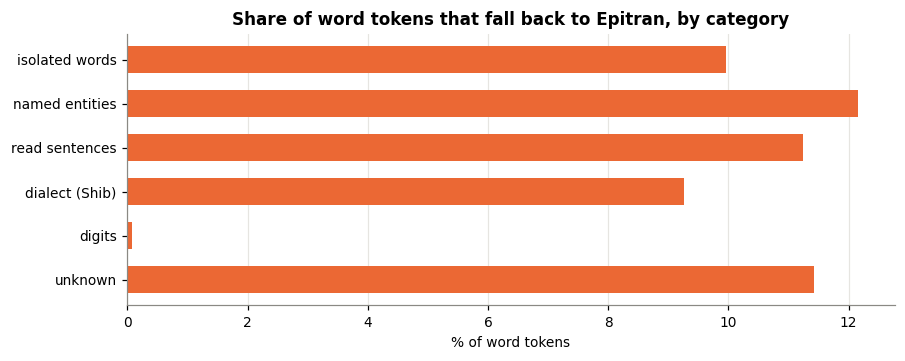

most frequent Epitran-fallback words:
{'Dok': 224, 'pinakamataas': 190, 'Maricel': 154, 'nasabing': 152, 'kumpara': 140, 'pagtaas': 137, 'engkantado': 133, 'Pupunta': 132, 'Tutugtog': 131, 'Pumalo': 129, 'Sinabi': 129, 'sinabi': 127, 'pumalo': 121, 'umabot': 118, 'Puerto': 110, 'lumalangoy': 108, 'Masulat': 106, 'Tumaas': 103, 'Inatawag': 102, 'Amomongo': 100, 'Atulungan': 99, 'nakatira': 96, 'Nahihirapan': 95, 'Pagpalain': 93, 'nakalipas': 92, 'tumubo': 92, 'magsara': 91, 'pagsusuri': 89, 'nakikita': 88, 'pagbaba': 86, 'Mactan': 84, 'tumaas': 84, 'Magkita': 84, 'bibigyan': 77, 'pagkawala': 77, 'pamamaraan': 76, 'Tiniyak': 75, 'Princesa': 74, 'Ipagpaumanhin': 73, 'Piñas': 73, 'Nawawala': 71, 'pagiging': 69, 'maparine': 69, 'lutui': 69, 'Punasi': 69, 'tuluyang': 69, 'namitas': 68, 'nagbibigay': 68, 'Itinuturo': 67, 'duon': 67}


In [33]:
fig, ax = plt.subplots(figsize=(9, 3.2))
cat_share = []
for cat in ["isolated words", "named entities", "read sentences", "dialect (Shib)", "digits", "unknown"]:
    texts = df.loc[(df.category == cat), "spoken_text"]
    srcs = Counter(src for t, n in texts.value_counts().items() for _, _, src in converted.get(t, []) for _ in range(n))
    total = sum(srcs.values()) or 1
    cat_share.append((cat, srcs["epitran"] / total))
cats, shares = zip(*cat_share)
ax.barh(cats[::-1], [100 * s for s in shares[::-1]], color=ORANGE, height=0.6)
ax.set(title="Share of word tokens that fall back to Epitran, by category", xlabel="% of word tokens")
ax.grid(axis="y", visible=False)
plt.show()
print("most frequent Epitran-fallback words:")
print(src_df[src_df.source == "epitran"].groupby("word").utterances.sum().sort_values(ascending=False).head(50).to_dict())

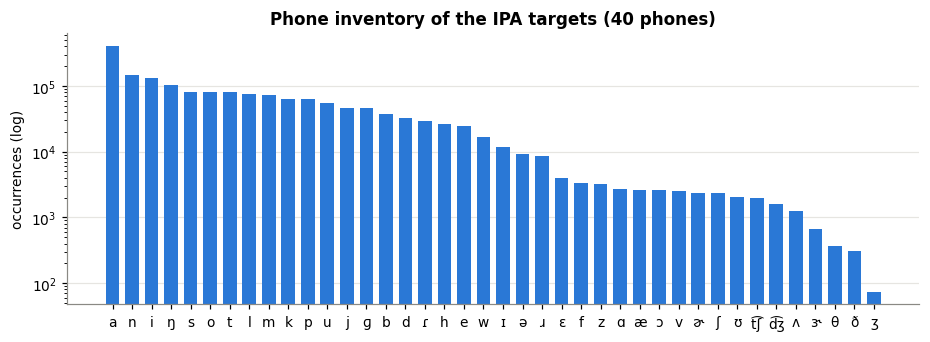

rare phones (< 100 occurrences) and where they come from:


  ʒ: 73  {'wiktionary-en': 50, 'derived-en': 3}


In [34]:
inventory = Counter(p for ipa, n in df.loc[df.ipa != "", "ipa"].value_counts().items() for p in phones(ipa) for _ in range(n))
inv = pd.Series(inventory).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(inv)), inv.values, color=BLUE, width=0.7)
ax.set_xticks(range(len(inv)), inv.index)
ax.set(title=f"Phone inventory of the IPA targets ({len(inv)} phones)", ylabel="occurrences (log)", yscale="log")
ax.grid(axis="x", visible=False)
plt.show()
print("rare phones (< 100 occurrences) and where they come from:")
for p in inv[inv < 100].index:
    srcs = Counter(src for w, src, n in word_rows if p in phones(word2ipa(w)[0]))
    print(f"  {p}: {inventory[p]}  {dict(srcs.most_common(3))}")

**Interpretation.**
- **~89% of word tokens get a Wiktionary pronunciation**, directly or through an exact rule: Tagalog entries 71.6%, linker/clitic derivations 7.9%, English entries 6.5% (WikiPron, plus English Wiktionary entries fetched from kaikki.org for words WikiPron misses, e.g. `Philippine`, `eighteen`), plus hyphen splits, acronyms and numbers. Names whose reading was chosen from the recordings (section 7.8) are 0.4%.
- **Epitran handles the remaining 11.0% of tokens** (4,347 types). The fallback words are mostly:
  - affixed verbs that Wiktionary lists only under their root (`sinabi`, `pumalo`, `pinakamataas`, `nakikita`)
  - names (`Maricel`, `Mactan`, `Amomongo`)
  - abbreviations and words with no Wiktionary entry at all (`Dok`, `Puerto`)
- **About 62% of usable utterances (31.2k of 50.7k) have no Epitran word.** The rest contain at least one; with ~92% word accuracy (section 7.4), most of those transcriptions are still exactly right.
- **The phone inventory has 40 phones**, with no glottal stop. The 20 most frequent are Tagalog phones (`a n i ŋ s t o l m ...`). English-only vowels and consonants (`ɪ ə ɹ ɛ æ ɑ ɔ ʊ ɚ θ ð`) come from the English words and each make up < 3% of phones.
- **Caveat on English vowels:** English words get **dictionary US-English pronunciations**, but Filipino speakers typically realise them with Tagalog vowels (e.g. `very` closer to [beɾi] than /vɛɹi/). If the model should transcribe what Filipino speakers actually say, consider mapping English vowels onto the Tagalog five-vowel system. That is a modelling choice, and it is left for later.

## 8. Output file

`FIL_g2p.csv` (next to the `FIL` folder) has one row per utterance line, except the spontaneous recordings, with audio path, speaker metadata and:

| column | meaning |
|---|---|
| `raw_text` | text from the log, unchanged |
| `text` | cleaned grapheme transcript |
| `spoken_text` | `text` with listener-confirmed readings substituted (`SPOKEN_READINGS`); this is what G2P converts |
| `has_manual_reading` | True if `spoken_text` uses a listener-confirmed reading |
| `ipa` | **training target**: broad IPA, no stress, no glottal stops, no spaces |
| `ipa_words` | the same with spaces between words |
| `word_sources` | per word: `wiktionary-tl`, `wiktionary-en`, `derived-tl`, `derived-en`, `hyphen-split`, `number`, `acronym`, `name-recordings`, `epitran` |
| `epitran_words` | words that had no Wiktionary pronunciation |
| `needs_review` | digits outside the `Random Digit` prompts with no confirmed reading (English vs Tagalog unknown) |
| `wav_exists` | False for the 7 speaker folders that ship only logs |
| `wav_readable`, `empty_audio` | WAV header readable; recording shorter than 0.1 s |

Spontaneous speech is **not in this file** (section 5).

`FIL_name_readings.csv` lists every name checked in section 7.8: candidates, distances to the recordings, and whether the reading changed.

The train/validation/test split is drawn from this file by `scripts/data_loaders/PLD_FIL.py` (speaker-disjoint and balanced, with 10% of prompts held out of training; see the fine-tuning notebook, section 2).

Suggested training filter: `wav_readable & ~empty_audio & ~needs_review`.

In [35]:
spk_cols = ["SpeakerID", "SpeakerAge", "SpeakerGender", "SpeakerDialect", "MotherDialect", "FatherDialect", "SpeakerProfession"]
# spontaneous speech is left out: there is no proper label for it yet (section 5)
out = df[~df.needs_transcription].merge(speakers[spk_cols], on="SpeakerID", how="left")
cols = ["wav", "wav_exists", "wav_readable", "empty_audio", "duration_s", "SpeakerID", "SessionID", "category", "prompt_file", "raw_text", "text", "spoken_text", "has_manual_reading", "ipa", "ipa_words", "word_sources", "epitran_words", "has_digits", "needs_review"] + spk_cols[1:]  # fmt: skip
out = out[cols]
out.to_csv(OUT_CSV, index=False)
sessions_df.to_csv(OUT_SPEAKERS_CSV, index=False)
usable = out.wav_readable & ~out.empty_audio & ~out.needs_review & (out.ipa != "")
assert not out.ipa.str.contains("ʔ").any(), "glottal stops left in the labels"
print(f"saved {len(out):,} rows -> {OUT_CSV} (left out: {df.needs_transcription.sum()} spontaneous recordings with no proper label)")
print(f"saved {len(sessions_df)} sessions -> {OUT_SPEAKERS_CSV}")
print(f"usable for training: {usable.sum():,} utterances, {out.loc[usable, 'duration_s'].sum() / 3600:.1f} h")
out[usable].sample(8, random_state=0)[["category", "text", "ipa_words", "word_sources"]]

saved 52,179 rows -> /home/joms/PycharmProjects/ML/.data/MDC/UP-DSP-PLD/PLD/FIL_g2p.csv (left out: 298 spontaneous recordings with no proper label)
saved 138 sessions -> /home/joms/PycharmProjects/ML/.data/MDC/UP-DSP-PLD/PLD/FIL_speakers.csv
usable for training: 50,681 utterances, 48.5 h


,category,text,ipa_words,word_sources
30008,read sentences,"Kung hindi ukol, hindi bubukol.",kuŋ hindi ukol hindi bubukol,wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl epitran
33806,read sentences,Nakahanda na ang hapúnan nang dumating siya. Ang punong iyon ang hapunán ng mga manok.,nakahanda na aŋ hapunan naŋ dumatiŋ sija aŋ punoŋ ijon aŋ hapunan naŋ maŋa manok,epitran wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl derived-tl...
35347,isolated words,kabayan,kabajan,wiktionary-tl
32285,isolated words,labì,labi,wiktionary-tl
2783,isolated words,San Miguel,san miɡel,wiktionary-tl wiktionary-tl
15175,isolated words,Guihulngan,ɡihulŋan,epitran
25124,read sentences,Naglaro naman ang palitan ng dolyar kahapon sa pagitan ng apatnapu't walong piso at animnapu't limang sentimo hangga...,naɡlaɾo naman aŋ palitan naŋ doljaɾ kahapon sa paɡitan naŋ apatnaput waloŋ piso at animnaput limaŋ sentimo haŋɡaŋ ap...,epitran wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-tl wiktionary...
46380,read sentences,"Ayon sa mga trader, malaking bagay ang pag-lift sa naturang direktiba dahil maraming mga negosyante ang nakipagsapal...",ajon sa maŋa tɹeɪdɚ malakiŋ baɡaj aŋ paɡlɪft sa natuɾaŋ diɾektiba dahil maɾamiŋ maŋa neɡosjante aŋ nakipaɡsapalaɾan ...,wiktionary-tl wiktionary-tl wiktionary-tl wiktionary-en derived-tl wiktionary-tl wiktionary-tl hyphen-split wiktiona...


## 9. Summary and limitations

**Dataset**
- 136 Tagalog speakers (60% female, median age 19.5, mostly students from Southern Tagalog and Central Luzon); 52.1 h of 16 kHz audio.
- Mostly **read speech**: sentences 69%, isolated words 18%, dialect prompts, digits and named entities. The rest is 3.6 h of spontaneous answers.
- 7 speaker folders have no audio, and 1 WAV is truncated.
- Prompts are reused ~8 times each, so **train/test splits should be disjoint by both speaker and prompt**.

**Transcripts**
- The log text needed cleaning: glosses and dialect notes in `()`, nested quotes, mojibake, `/`-joined sentence pairs.
- **Spontaneous speech (298 recordings, 3.6 h) is not used for now.** This is because of the nature of its transcription: the log text is the interviewer's question, not what was said, so there is no proper label. It is excluded from G2P and from the output file until it is transcribed.

**G2P**
- Wiktionary broad IPA (kaikki.org for Tagalog; WikiPron, then kaikki.org's English extract, for English) covers ~89% of word tokens, directly or via exact linker/clitic/inflection rules.
- The remaining 11% use Epitran `tgl-Latn` plus six correction rules. Each rule was tested on held-out Wiktionary words: 86.8% → 92.5% word accuracy, PER 3.1% → 1.5%.
- **No glottal stops**: `ʔ` is removed from every label (section 7.1).
- **Names** not in Tagalog Wiktionary were checked against the recordings: 62 of 205 got the reading the speakers actually used (section 7.8; reproducible from `FIL_names_pretrained_asr.jsonl`, made by `scripts/data_loaders/PLD_FIL_names_asr.py`).
- Digits are spelled out in Tagalog, based on a spot check of the digit recordings. Acronyms use the Filipino letter names from Wiktionary.

**Listener-confirmed readings:** `SPOKEN_READINGS` records how prompts with digits or codes were actually read (`Hotel H2O` → *Hotel H two O*, `Taung 1895` → *eighteen ninety-five*), covering 18 recordings so far. G2P runs on the resulting `spoken_text`.

**Output:** `FIL_g2p.csv`, with 50,681 utterances (48.5 h, 129 speakers, 6,411 distinct prompts) passing the suggested training filter.

**Limitations**
- **Canonical, not phonetic.** The targets are dictionary (Standard Tagalog) pronunciations of the *prompt*. They do not capture regional realisations, reading errors, or disfluencies in the audio.
- **Homographs** without written accents take Wiktionary's first entry, which can be the wrong reading in context. English homographs likewise take WikiPron's first pronunciation (`row` → /ɹaʊ/).
- **No glottal stops.** Removing `ʔ` merges a few minimal pairs (`bata` "child" /bataʔ/ and "endurance" /bata/ are now both `bata`).
- **Glides** in Epitran-fallback words (`dia` /dija/) are the main remaining G2P error.
- **English words** use US-English pronunciations, which overstate the vowel contrasts most Filipino speakers make (section 7.7).
- **Number readings** in non-digit prompts with no confirmed reading yet (`$62.7 billion`, `LRT1`, `Free T3`) are uncertain; these 14 recordings (13 prompts) are flagged `needs_review`. Add their readings to `SPOKEN_READINGS` to clear them.
- **Stress is removed** everywhere for consistency, although Wiktionary has it for Tagalog and it is contrastive (`bata` vs `batá`).